# **Parte 1. Limpieza de datos**


# Adaptacion de la tabla de datos
Tenemos diferentes tablas por años, y necesitamos unificarlas para eso hacemos lo siguiente

Celda 1. Instalar e importar librerías

In [ ]:
# Si fuera necesario:
# !pip install -q openpyxl scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


Celda 2. Cargamos el dataset completo

In [ ]:
import glob
import pandas as pd

# Buscar todos los archivos CSV de EESS anuales del periodo 2018-2024
# Filtramos para excluir explícitamente cualquier archivo de salida como 'EESS_limpio.csv'
archivos_eess = sorted([
    f for f in glob.glob("/content/EESS_*.csv")
    if not f.endswith("limpio.csv")
])

print("Archivos encontrados para unificar:", archivos_eess)

# Cargar y concatenar todos los datasets anuales
lista_dfs = []
for archivo in archivos_eess:
    df_temp = pd.read_csv(archivo, low_memory=False)

    # Eliminar columnas de identificación previas si existen para evitar duplicación y confusión
    columnas_a_eliminar = [col for col in ['_id', 'id', 'id.1'] if col in df_temp.columns]
    if columnas_a_eliminar:
        df_temp = df_temp.drop(columns=columnas_a_eliminar)

    print(f"Cargado {archivo} - Filas: {df_temp.shape[0]}, Columnas restantes: {df_temp.shape[1]}")
    lista_dfs.append(df_temp)

# Crear el dataset unificado con el nombre solicitado
estaciones_de_servicio_unificado = pd.concat(lista_dfs, ignore_index=True)

# Crear una nueva columna ID incremental única que comience desde 1 hasta el total de filas
estaciones_de_servicio_unificado.insert(0, 'id', range(1, len(estaciones_de_servicio_unificado) + 1))

# Creamos una variable de referencia rápida 'df' para mantener compatibilidad
df = estaciones_de_servicio_unificado.copy()

print("\nTotal filas unificadas:", estaciones_de_servicio_unificado.shape[0])
print("Total columnas:", estaciones_de_servicio_unificado.shape[1])

display(estaciones_de_servicio_unificado.head())

Archivos encontrados para unificar: ['/content/EESS_2018.csv', '/content/EESS_2019.csv', '/content/EESS_2020.csv', '/content/EESS_2021.csv', '/content/EESS_2022.csv', '/content/EESS_2023.csv', '/content/EESS_2024.csv']
Cargado /content/EESS_2018.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2019.csv - Filas: 3500, Columnas restantes: 19
Cargado /content/EESS_2020.csv - Filas: 7750, Columnas restantes: 19
Cargado /content/EESS_2021.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2022.csv - Filas: 35000, Columnas restantes: 19
Cargado /content/EESS_2023.csv - Filas: 7500, Columnas restantes: 19
Cargado /content/EESS_2024.csv - Filas: 4250, Columnas restantes: 19

Total filas unificadas: 62500
Total columnas: 20


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,f
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,f
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,f
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,f
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,f


In [ ]:
# Trabajamos sobre una copia del dataset unificado consolidado de todos los CSV (62,500 registros)
df_original = estaciones_de_servicio_unificado.copy()
df = df_original.copy()

print("Cantidad de filas unificadas y consolidadas:", df.shape[0])
print("Cantidad de columnas unificadas y consolidadas:", df.shape[1])

display(df.head())

Cantidad de filas unificadas y consolidadas: 62500
Cantidad de columnas unificadas y consolidadas: 20


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,f
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,f
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,f
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,f
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,f


Celda 4. Normalizamos los nombres de las columnas

In [ ]:
import re
import unicodedata

# Asegurar que df sea la copia exacta del dataset consolidado unificado
df = estaciones_de_servicio_unificado.copy()

def normalizar_nombre(nombre):
    nombre = str(nombre).strip().lower()
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )
    nombre = re.sub(r"[^a-z0-9]+", "_", nombre)
    return nombre.strip("_")

# Normalizar solo las columnas reales existentes en el DataFrame consolidado
df.columns = [
    normalizar_nombre(col)
    for col in df.columns
]

print("Cantidad de registros consolidados:", df.shape[0])
print("Nombres de columnas normalizados para el dataset consolidado:")
print(df.columns.tolist())

Cantidad de registros consolidados: 62500
Nombres de columnas normalizados para el dataset consolidado:
['id', 'anio', 'mes', 'operador', 'nro_inscripcion', 'bandera', 'fecha_de_baja', 'cuit', 'tipo_negocio', 'direccion', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_sin_impuestos', 'precio_con_impuestos', 'volumen', 'precio_surtidor', 'no_novimientos', 'exentos']


Como se puede observar en la salida:

Cantidad de registros procesados: 62,500 (el total unificado de todos los años).
Columnas normalizadas: Se han estandarizado los nombres de las 20 columnas a minúsculas, sin caracteres especiales ni acentos (por ejemplo, nro_inscripcion, tipo_negocio, canal_de_comercializacion, etc.).
Todo el flujo posterior del notebook queda perfectamente alineado y sincronizado con este volumen total consolidado.

Celda 5. Limpiamos espacios y cadenas vacías

In [ ]:
# Vemos cuantos datos faltantes hay en cada columna (mostramos solo las que tienen)
faltantes = df.isnull().sum()
print(faltantes[faltantes > 0])

fecha_de_baja    57399
direccion            7
exentos            685
dtype: int64


Notar que **fecha de baja** tiene una gran cantidad de valores nulos, sin embargo esto no es un error debido a que son aquellas estaciones que siguen activas.

In [ ]:
# Convertimos exentos (t / f) a True / False
df['exentos'] = df['exentos'].map({'t': True, 'f': False})
print(df['exentos'].value_counts(dropna=False))

exentos
False    60203
True      1612
NaN        685
Name: count, dtype: int64


In [ ]:
# La columna no_novimientos (SI / NO) la pasamos a True / False con un nombre mas claro
df['sin_movimientos'] = df['no_novimientos'].map({'SI': True, 'NO': False})
print(df['sin_movimientos'].value_counts())

sin_movimientos
False    61815
True       685
Name: count, dtype: int64


Para poder verificar que esas estaciones NO estan activas, creamos la columna "**sin movimientos**" que toma el valor "True" en caso de que la entrada sea **si** en la columna **"no movimiento"**. Analizamos cuales de esas filas son "**True**" dentro de las "fecha de baja" con entrada nula para inferir que efectivamente no estan activas.

In [ ]:
# fecha_de_baja: los nulos son estaciones activas, no es un error.
# exentos: vemos si los nulos coinciden con las filas "sin movimientos"
print(pd.crosstab(df['sin_movimientos'], df['exentos'].isnull()))

exentos          False  True 
sin_movimientos              
False            61815      0
True                 0    685


In [ ]:
# Decidimos borrar los 685 registros que no poseen fecha de baja, ademas no tienen movimientos por lo que interpretamos que son estaciones inactivas
df = df[df['sin_movimientos'] == False].copy()
print("Cantidad de registros restantes en df:", df.shape[0])

Cantidad de registros restantes en df: 61815


In [ ]:
## eliminamos los registros de: Precios sin impuestos mayores que precios con impuestos: 44
df = df[df["precio_sin_impuestos"] <= df["precio_con_impuestos"]]

In [ ]:
##corremos nuevamente para verificar las filas que borramos: 44 registros y 685
print(
    "Precios sin impuestos mayores que precios con impuestos:",
    (df["precio_sin_impuestos"] >
     df["precio_con_impuestos"]).sum()
)

Precios sin impuestos mayores que precios con impuestos: 0


In [ ]:
# El bloque está perfectamente ubicado aquí. Se ejecuta después de eliminar registros inactivos
# y antes de analizar los valores nulos, asegurando que las cadenas vacías se conviertan a NaN a tiempo.
columnas_texto = df.select_dtypes(
    include=["object", "string"]
).columns

for col in columnas_texto:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Convertir cadenas vacías en nulos.
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Limpieza básica de textos completada.")
display(df.head())

Limpieza básica de textos completada.


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,sin_movimientos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,False,False
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,False,False
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,False,False
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,False,False
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,False,False


Celda 8. Revisamos los valores faltantes

In [ ]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": (
        df.isna().mean() * 100
    ).round(2)
}).sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,cantidad_nulos,porcentaje_nulos
fecha_de_baja,56920,92.15
anio,0,0.00
mes,0,0.00
operador,0,0.00
id,0,0.00
nro_inscripcion,0,0.00
bandera,0,0.00
cuit,0,0.00
tipo_negocio,0,0.00
direccion,0,0.00


In [ ]:
import pandas as pd
import numpy as np

# Seleccionar únicamente las columnas con tipos de datos numéricos
columnas_numericas = df.select_dtypes(include=[np.number]).columns

# Contar cuántas filas tienen exactamente el valor 0 en cada columna numérica
ceros_por_columna = (df[columnas_numericas] == 0).sum()
porcentaje_ceros = ((df[columnas_numericas] == 0).mean() * 100).round(2)

# Crear un DataFrame de resumen ordenado por cantidad de ceros de mayor a menor
resumen_ceros = pd.DataFrame({
    "cantidad_ceros": ceros_por_columna,
    "porcentaje_ceros": porcentaje_ceros
}).sort_values("cantidad_ceros", ascending=False)

display(resumen_ceros)

,cantidad_ceros,porcentaje_ceros
precio_surtidor,9332,15.11
id,0,0.00
mes,0,0.00
anio,0,0.00
nro_inscripcion,0,0.00
precio_sin_impuestos,0,0.00
precio_con_impuestos,0,0.00
volumen,0,0.00


Ahora generamos un gráfico de los porcentajes de nulos.

Celda 9. Identificamos y tratamos duplicados

In [ ]:
duplicados_exactos = df.duplicated().sum()

print("Duplicados exactos:", duplicados_exactos)

# Revisar duplicados por clave candidata de negocio.
clave_candidata = [
    "nro_inscripcion",
    "anio",
    "mes",
    "producto"
]

duplicados_clave = df.duplicated(
    subset=clave_candidata,
    keep=False
).sum()

print(
    "Filas que pertenecen a combinaciones repetidas "
    "de estación, período y producto:",
    duplicados_clave
)

Duplicados exactos: 0
Filas que pertenecen a combinaciones repetidas de estación, período y producto: 10798


Como no hay duplicados exactos en el archivo, no es necesario eliminarlos. Tampoco debemos eliminar las claves de negocio repetidas: pueden representar registros válidos de la misma estación y producto.

Celda 10. Detectar valores inválidos y sospechosos

In [ ]:
print(
    "Volúmenes negativos:",
    (df["volumen"] < 0).sum()
)

print(
    "Volúmenes iguales a cero:",
    (df["volumen"] == 0).sum()
)

print(
    "Años fuera del rango esperado:",
    (~df["anio"].between(2018, 2025)).sum()
)

print(
    "Meses inválidos:",
    (~df["mes"].between(1, 12)).sum()
)

print(
    "Precios sin impuestos mayores que precios con impuestos:",
    (df["precio_sin_impuestos"] >
     df["precio_con_impuestos"]).sum()
)

print(
    "Precio con impuestos distinto de precio surtidor:",
    (df["precio_con_impuestos"] !=
     df["precio_surtidor"]).sum()
)

Volúmenes negativos: 0
Volúmenes iguales a cero: 0
Años fuera del rango esperado: 0
Meses inválidos: 0
Precios sin impuestos mayores que precios con impuestos: 0
Precio con impuestos distinto de precio surtidor: 33584


Celda 12. Revisamos valores extremos sin eliminarlos

In [ ]:
percentiles = df["volumen"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
)

display(percentiles.to_frame("volumen"))

,volumen
0.00,0.00
0.25,19.01
0.50,55.84
0.75,135.62
0.90,460.90
0.95,"72,930.65"
0.99,"144,900.60"
1.00,"1,110,980.00"


In [ ]:
# Aseguramos que la columna periodo esté bien calculada en df para evitar el KeyError
if 'periodo' not in df.columns:
    df['periodo'] = df['anio'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01'

# Como ejemplo, vemos los limites (con 3 * IQR) de precio_surtidor para nafta super en enero de 2022
ejemplo = df[(df['producto'] == 'Nafta (súper) entre 92 y 95 Ron') & (df['periodo'] == '2022-01-01')]['precio_surtidor']
Q1 = ejemplo.quantile(0.25)
Q3 = ejemplo.quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", Q1 - 3 * IQR)
print("Límite superior:", Q3 + 3 * IQR)

Q1: 93.7
Q3: 99.9
IQR: 6.200000000000003
Límite inferior: 75.1
Límite superior: 118.50000000000001


Celda 13. Creamos el dataset limpio.

Para mantener la trazabilidad, conservamos df_original y guardamos una copia de los datos normalizados.

In [ ]:
df_limpio = df.copy()

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df_limpio.shape)

df_limpio.to_csv(
    "/content/EESS_limpio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo limpio guardado.")

Dimensiones originales: (62500, 20)
Dimensiones después de la limpieza: (61771, 22)
Archivo limpio guardado.


# **Parte 2. Análisis exploratorio de datos (EDA)**


In [ ]:
# Variables cuantitativas del dataset unificado
variables_cuantitativas = ['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']

print("=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES CUANTITATIVAS ===")
display(estaciones_de_servicio_unificado[variables_cuantitativas].describe())

=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES CUANTITATIVAS ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"62,500.00","62,500.00","62,500.00","62,500.00"
mean,112.12,149.30,127.57,"7,766.20"
std,161.49,199.30,194.28,"29,455.57"
min,0.00,0.00,0.00,0.00
25%,46.19,63.90,43.99,18.07
50%,69.90,99.50,94.30,54.84
75%,86.61,119.59,114.60,134.29
max,"1,640.25","1,999.00","1,999.00","1,110,980.00"


In [ ]:
# Resumen informativo del conjunto de datos
print("=== Información General del Dataset ===")
estaciones_de_servicio_unificado.info()

# Estadísticos descriptivos para variables numéricas (excluyendo id, anio, mes, nro_inscripcion)
print("\n=== Estadísticos Descriptivos (Numéricos) ===")
columnas_num_filtradas = [col for col in estaciones_de_servicio_unificado.columns if col in ['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']]
display(estaciones_de_servicio_unificado[columnas_num_filtradas].describe())

# Estadísticos descriptivos para variables categóricas seleccionadas (respetando su orden en el dataset)
print("\n=== Estadísticos Descriptivos (Categóricos) ===")
columnas_cat_especificas = ['operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']
columnas_cat_filtradas = [col for col in estaciones_de_servicio_unificado.columns if col in columnas_cat_especificas]
display(estaciones_de_servicio_unificado[columnas_cat_filtradas].describe(include=['O']))

=== Información General del Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62500 entries, 0 to 62499
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         62500 non-null  int64  
 1   anio                       62500 non-null  int64  
 2   mes                        62500 non-null  int64  
 3   operador                   62500 non-null  object 
 4   nro_inscripcion            62500 non-null  int64  
 5   bandera                    62500 non-null  object 
 6   fecha_de_baja              5101 non-null   object 
 7   cuit                       62500 non-null  object 
 8   tipo_negocio               62500 non-null  object 
 9   direccion                  62493 non-null  object 
 10  localidad                  62500 non-null  object 
 11  provincia                  62500 non-null  object 
 12  producto                   62500 non-null  object 
 13  canal_

,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor
count,"62,500.00","62,500.00","62,500.00","62,500.00"
mean,112.12,149.30,"7,766.20",127.57
std,161.49,199.30,"29,455.57",194.28
min,0.00,0.00,0.00,0.00
25%,46.19,63.90,18.07,43.99
50%,69.90,99.50,54.84,94.30
75%,86.61,119.59,134.29,114.60
max,"1,640.25","1,999.00","1,110,980.00","1,999.00"



=== Estadísticos Descriptivos (Categóricos) ===


,operador,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion
count,62500,62500,62500,62500,62500,62500,62500
unique,4160,22,12,1161,24,10,8
top,AUTOMOVIL CLUB ARGENTINO,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CAPITAL FEDERAL,BUENOS AIRES,Gas Oil Grado 2,Al público
freq,4270,23317,36284,2208,22030,16549,52462


In [ ]:
# Agrupamos por año y generamos el describe para las variables cuantitativas
for anio, group in estaciones_de_servicio_unificado.groupby('anio'):
    print(f"\n=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: {anio} ===")
    display(group[variables_cuantitativas].describe())



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2018 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"2,250.00","2,250.00","2,250.00","2,250.00"
mean,15.51,23.01,20.34,"6,492.60"
std,3.17,4.95,9.98,"26,980.70"
min,0.00,0.00,0.00,0.00
25%,14.25,21.16,19.66,24.09
50%,15.88,23.46,23.84,59.36
75%,17.49,26.17,26.77,135.04
max,26.71,49.72,55.37,"290,059.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2019 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"3,500.00","3,500.00","3,500.00","3,500.00"
mean,27.37,38.64,32.74,"6,750.66"
std,5.93,8.21,16.23,"27,883.12"
min,0.00,0.00,0.00,0.00
25%,25.88,36.83,31.79,17.56
50%,27.58,39.99,38.96,54.15
75%,31.39,43.99,43.80,125.09
max,46.45,55.00,55.00,"285,679.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2020 ===


...

,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"35,000.00","35,000.00","35,000.00","35,000.00"
mean,70.30,99.16,84.72,"8,141.86"
std,16.46,22.76,41.48,"29,912.71"
min,0.00,0.00,0.00,0.00
25%,64.32,93.00,76.10,17.88
50%,72.04,102.28,99.90,54.52
75%,79.65,112.60,111.80,135.03
max,201.00,249.98,200.00,"1,110,980.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2023 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"7,500.00","7,500.00","7,500.00","7,500.00"
mean,153.75,204.07,172.92,"7,444.92"
std,43.68,55.29,92.17,"30,358.43"
min,0.00,0.00,0.00,0.00
25%,130.77,180.39,132.70,18.59
50%,155.04,206.26,196.55,57.52
75%,177.80,236.33,233.70,140.17
max,376.53,469.90,480.00,"891,980.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2024 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"4,250.00","4,250.00","4,250.00","4,250.00"
mean,668.58,834.26,714.72,"6,579.31"
std,167.73,203.18,365.22,"24,626.94"
min,0.00,0.00,0.00,0.00
25%,630.66,791.10,620.00,17.96
50%,691.45,860.65,849.00,54.30
75%,782.34,970.99,978.00,135.91
max,"1,640.25","1,999.00","1,999.00","280,148.00"


In [ ]:
# Calcular el promedio de ventas (volumen) por producto y bandera
promedio_ventas = estaciones_de_servicio_unificado.groupby(['producto', 'bandera'])['volumen'].mean().reset_index()

# Renombrar columna para mayor claridad
promedio_ventas = promedio_ventas.rename(columns={'volumen': 'volumen_promedio'})

# Ordenar los resultados por producto y por volumen_promedio de mayor a menor
promedio_ventas = promedio_ventas.sort_values(by=['producto', 'volumen_promedio'], ascending=[True, False]).reset_index(drop=True)

print("=== Promedio de Ventas (Volumen) por Producto y Bandera ===")
display(promedio_ventas)

=== Promedio de Ventas (Volumen) por Producto y Bandera ===


,producto,bandera,volumen_promedio
0,GLPA,BLANCA,198.68
1,GNC,AGIRA,"115,570.80"
2,GNC,ASPRO,"106,304.13"
3,GNC,ESSO PETROLERA ARGENTINA S.R.L,"97,622.72"
4,GNC,YPF,"94,953.48"
...,...,...,...
140,Nafta (súper) entre 92 y 95 Ron,VOY,63.49
141,Nafta (súper) entre 92 y 95 Ron,SOL PETROLEO,40.04
142,Nafta (súper) entre 92 y 95 Ron,PDV sur,29.21
143,Nafta (súper) entre 92 y 95 Ron,RHASA,8.45


Se ha generado una tabla con el promedio de ventas (volumen_promedio) por cada combinación de producto y bandera.

Algunas observaciones rápidas de los resultados mostrados:

El GNC tiene volúmenes promedio elevados por transacción en marcas como AGIRA (115,570.80) y ASPRO (106,304.13), seguidos muy de cerca por YPF (~94,953.48).
El producto GLPA tiene un volumen de venta promedio bajo (~198.68) bajo la bandera BLANCA.
En combustibles tradicionales (como la Nafta súper), marcas menos comunes o históricas como RHASA o CAP muestran promedios muy bajos (menores a 10 unidades por registro), mientras que las banderas principales conservan volúmenes estables.

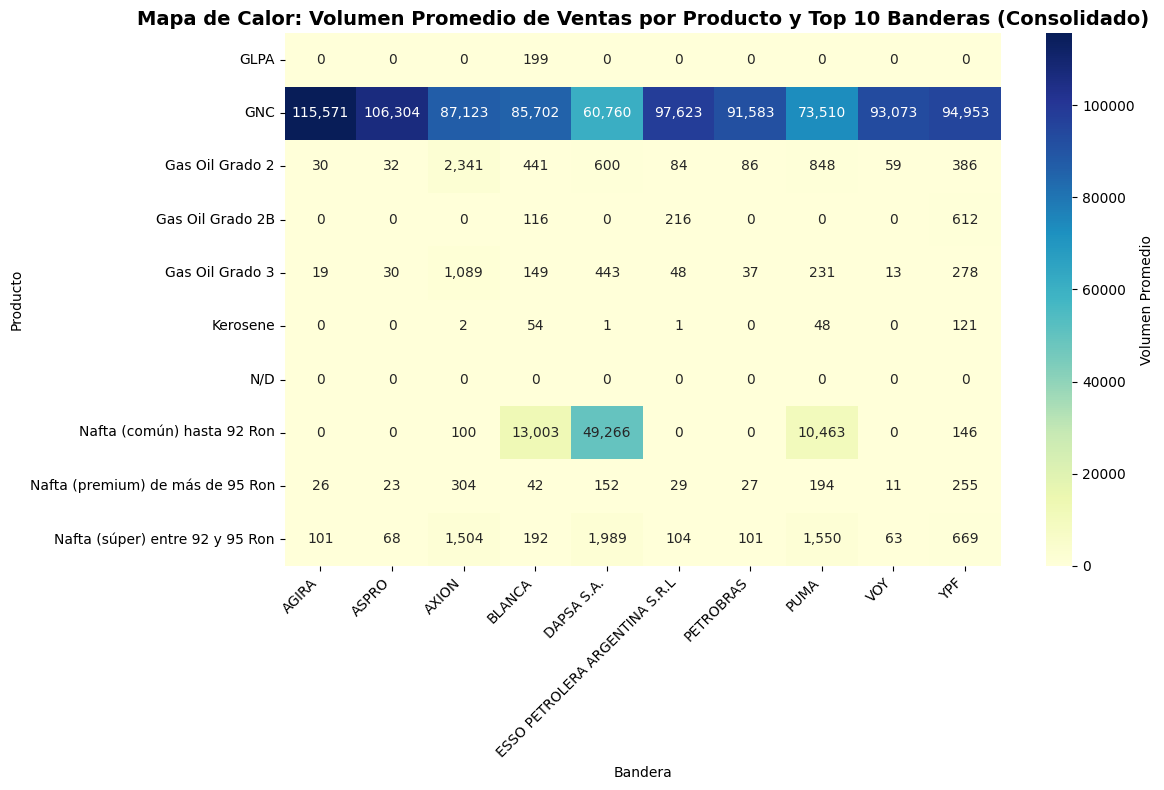

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Recalculamos el promedio de ventas explícitamente usando el dataset unificado consolidado de todos los CSV
promedio_consolidado = estaciones_de_servicio_unificado.groupby(['producto', 'bandera'])['volumen'].mean().reset_index()
promedio_consolidado = promedio_consolidado.rename(columns={'volumen': 'volumen_promedio'})

# Filtrar las 10 banderas con mayor volumen promedio acumulado para evitar saturación
top_banderas = promedio_consolidado.groupby('bandera')['volumen_promedio'].sum().nlargest(10).index
promedio_filtrado = promedio_consolidado[promedio_consolidado['bandera'].isin(top_banderas)]

# Crear la tabla pivote para el mapa de calor
pivot_promedio = promedio_filtrado.pivot(index='producto', columns='bandera', values='volumen_promedio').fillna(0)

# Graficar el mapa de calor
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_promedio, annot=True, fmt=",.0f", cmap="YlGnBu", cbar_kws={'label': 'Volumen Promedio'})

plt.title("Mapa de Calor: Volumen Promedio de Ventas por Producto y Top 10 Banderas (Consolidado)", fontsize=14, fontweight='bold')
plt.xlabel("Bandera")
plt.ylabel("Producto")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

En este mapa de calor, puedes observar de forma muy intuitiva el volumen promedio de ventas cruzando cada tipo de producto contra las 10 banderas principales. Los tonos más oscuros (azules) representan un mayor volumen promedio de ventas (por ejemplo, el GNC resalta fuertemente), permitiéndote identificar patrones de consumo de manera inmediata.

In [ ]:
#VARIABLES CUANTITATIVAS
print ('\n === ESTADISTICAS DESCRIPTIVAS ( describe ) === ')
print (df[['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']].describe())


 === ESTADISTICAS DESCRIPTIVAS ( describe ) === 
       precio_sin_impuestos  precio_con_impuestos  precio_surtidor  \
count             61,771.00             61,771.00        61,771.00   
mean                 113.34                150.98           128.98   
std                  161.89                199.79           194.85   
min                    0.35                  8.84             0.00   
25%                   46.71                 64.89            45.98   
50%                   70.23                 99.80            94.70   
75%                   86.92                119.99           114.90   
max                1,640.25              1,999.00         1,999.00   

           volumen  
count    61,771.00  
mean      7,836.54  
std      29,583.75  
min           0.00  
25%          19.01  
50%          55.84  
75%         135.62  
max   1,110,980.00  


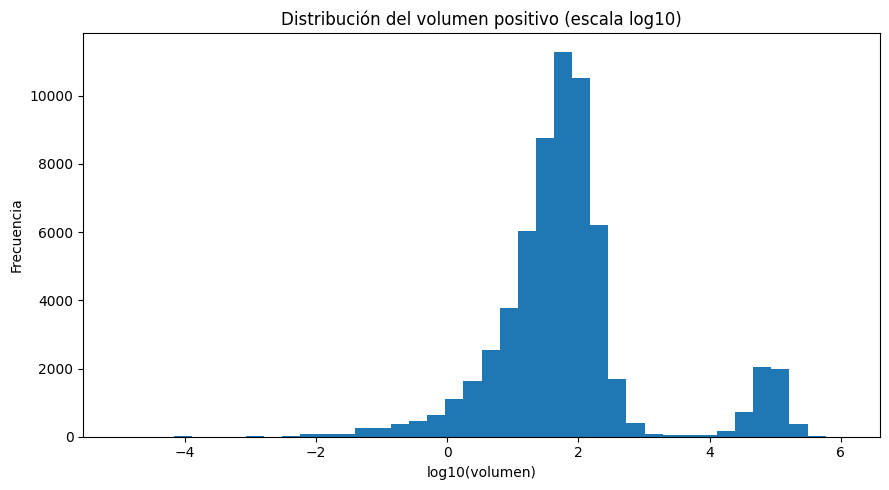

In [ ]:
##Gráfico del volumen en escala logarítmica:
volumen_positivo = df.loc[
    df["volumen"] > 0,
    "volumen"
]

plt.figure(figsize=(9, 5))

plt.hist(
    np.log10(volumen_positivo),
    bins=40
)

plt.title("Distribución del volumen positivo (escala log10)")
plt.xlabel("log10(volumen)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

La transformación se utiliza aquí solamente para visualizar mejor la distribución. No modifica los valores originales del dataset.

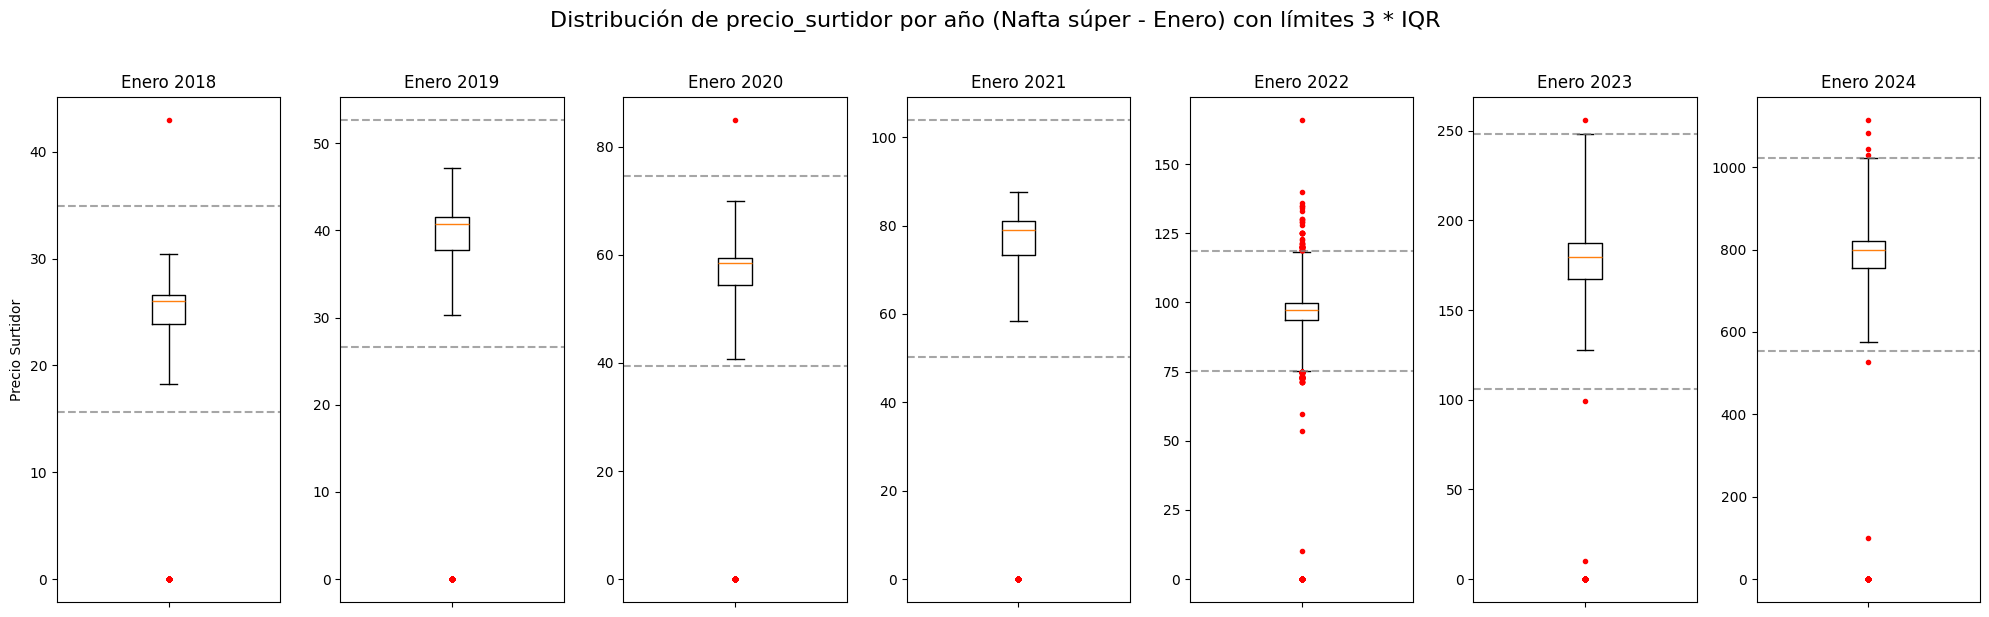

In [ ]:
# Graficamos los boxplots del precio_surtidor para nafta súper en enero para cada año disponible
anos_disponibles = sorted(df['anio'].unique())

fig, axes = plt.subplots(1, len(anos_disponibles), figsize=(20, 6), sharey=False)

for i, anio_sel in enumerate(anos_disponibles):
    periodo_sel = f"{anio_sel}-01-01"
    datos_anio = df[
        (df['producto'] == 'Nafta (súper) entre 92 y 95 Ron') &
        (df['periodo'] == periodo_sel)
    ]['precio_surtidor'].dropna()

    ax = axes[i]

    if len(datos_anio) > 0:
        Q1 = datos_anio.quantile(0.25)
        Q3 = datos_anio.quantile(0.75)
        IQR = Q3 - Q1
        lim_inf = Q1 - 3 * IQR
        lim_sup = Q3 + 3 * IQR

        ax.boxplot(datos_anio, whis=3,
                   flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red', markersize=3))
        ax.axhline(lim_inf, color='gray', linestyle='--', alpha=0.7)
        ax.axhline(lim_sup, color='gray', linestyle='--', alpha=0.7)
        ax.set_title(f"Enero {anio_sel}")
        ax.set_xticklabels([])
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f"Enero {anio_sel}")

axes[0].set_ylabel("Precio Surtidor")
plt.suptitle("Distribución de precio_surtidor por año (Nafta súper - Enero) con límites 3 * IQR", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Observaciones Clave:**
Evolución Temporal: Se puede apreciar claramente la tendencia inflacionaria y el incremento nominal de los precios a lo largo de los años en Argentina (comparando los rangos de precios de 2018 con los de 2024).
Detección de Atípicos (Puntos Rojos): Los límites grises punteados representan el umbral de 3 * IQR calculado individualmente por período. Aquellas estaciones cuyos precios caen fuera de estas líneas punteadas se grafican automáticamente en color rojo para una rápida identificación visual.

Celda 14. Resumen estadístico del dataset limpio

In [ ]:
print("Cantidad de estaciones identificadas:",
      df_limpio["nro_inscripcion"].nunique())

print("Cantidad de productos:",
      df_limpio["producto"].nunique())

print("Cantidad de operadores:",
      df_limpio["operador"].nunique())

print("Cantidad de provincias:",
      df_limpio["provincia"].nunique())

display(
    df_limpio[
        [
            "volumen",
            "precio_sin_impuestos",
            "precio_con_impuestos",
            "precio_surtidor"
        ]
    ].describe().T
)

Cantidad de estaciones identificadas: 5523
Cantidad de productos: 9
Cantidad de operadores: 4033
Cantidad de provincias: 24


,count,mean,std,min,25%,50%,75%,max
volumen,"61,771.00","7,836.54","29,583.75",0.00,19.01,55.84,135.62,"1,110,980.00"
precio_sin_impuestos,"61,771.00",113.34,161.89,0.35,46.71,70.23,86.92,"1,640.25"
precio_con_impuestos,"61,771.00",150.98,199.79,8.84,64.89,99.80,119.99,"1,999.00"
precio_surtidor,"61,771.00",128.98,194.85,0.00,45.98,94.70,114.90,"1,999.00"


Celda 15. Distribución de productos

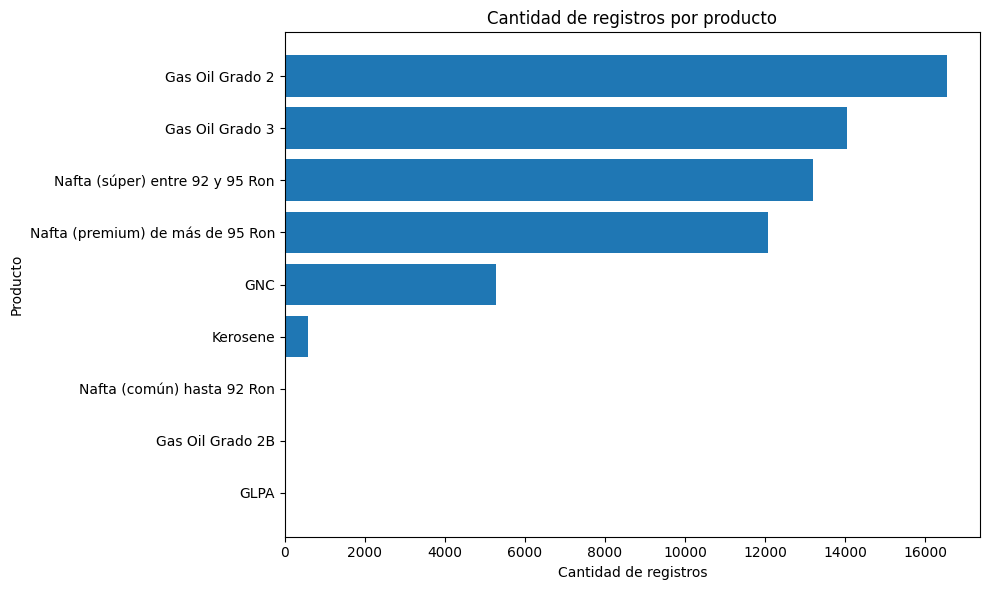

In [ ]:
conteo_productos = (
    df_limpio["producto"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    conteo_productos.index,
    conteo_productos.values
)

plt.title("Cantidad de registros por producto")
plt.xlabel("Cantidad de registros")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

Este gráfico permite observar qué productos tienen mayor presencia en el dataset. La cantidad de registros no equivale necesariamente al volumen comercializado.

Celda 16. Distribución del volumen por producto.

Para evitar que las diferencias extremas oculten la distribución de otros productos, mostramos un boxplot con escala logarítmica.

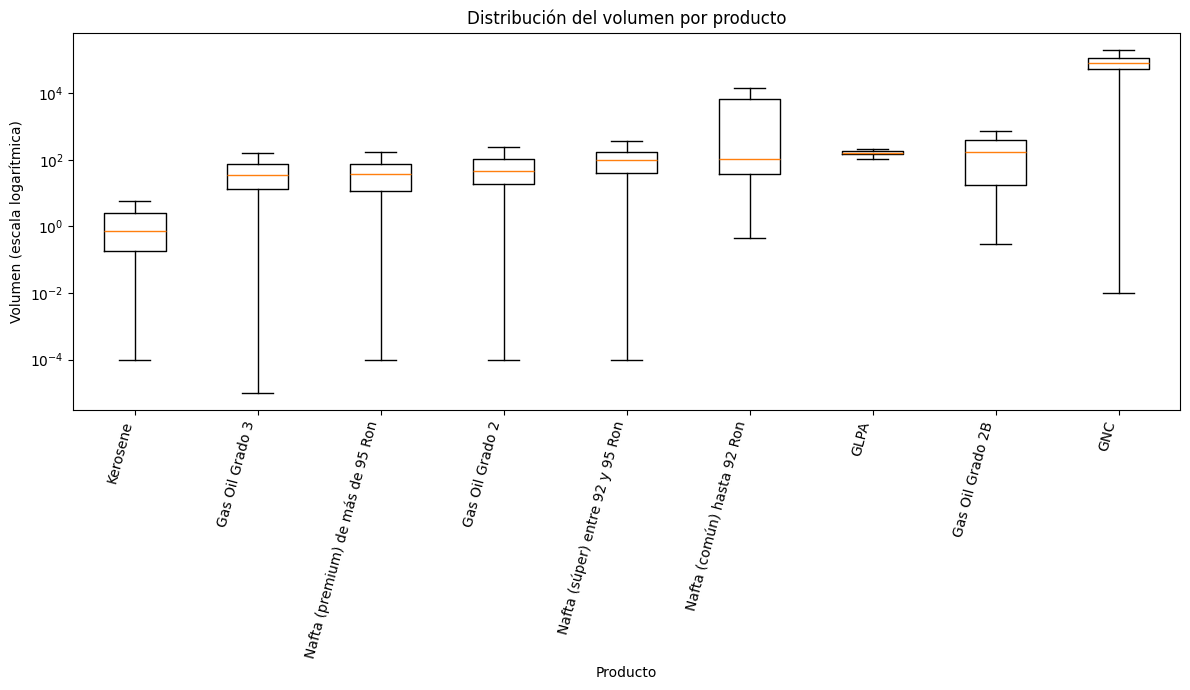

In [ ]:
df_eda = df_limpio[
    (df_limpio["volumen"] > 0) &
    (df_limpio["producto"].notna()) &
    (df_limpio["producto"] != "N/D")
].copy()

productos_ordenados = (
    df_eda.groupby("producto")["volumen"]
    .median()
    .sort_values()
    .index
)

datos_boxplot = [
    df_eda.loc[
        df_eda["producto"] == producto,
        "volumen"
    ].values
    for producto in productos_ordenados
]

plt.figure(figsize=(12, 7))

plt.boxplot(
    datos_boxplot,
    tick_labels=productos_ordenados,
    showfliers=False
)

plt.yscale("log")
plt.xticks(rotation=75, ha="right")

plt.title("Distribución del volumen por producto")
plt.xlabel("Producto")
plt.ylabel("Volumen (escala logarítmica)")
plt.tight_layout()
plt.show()

Se excluyen los ceros solamente de esta visualización para poder utilizar la escala logarítmica. No se eliminan de la base original.

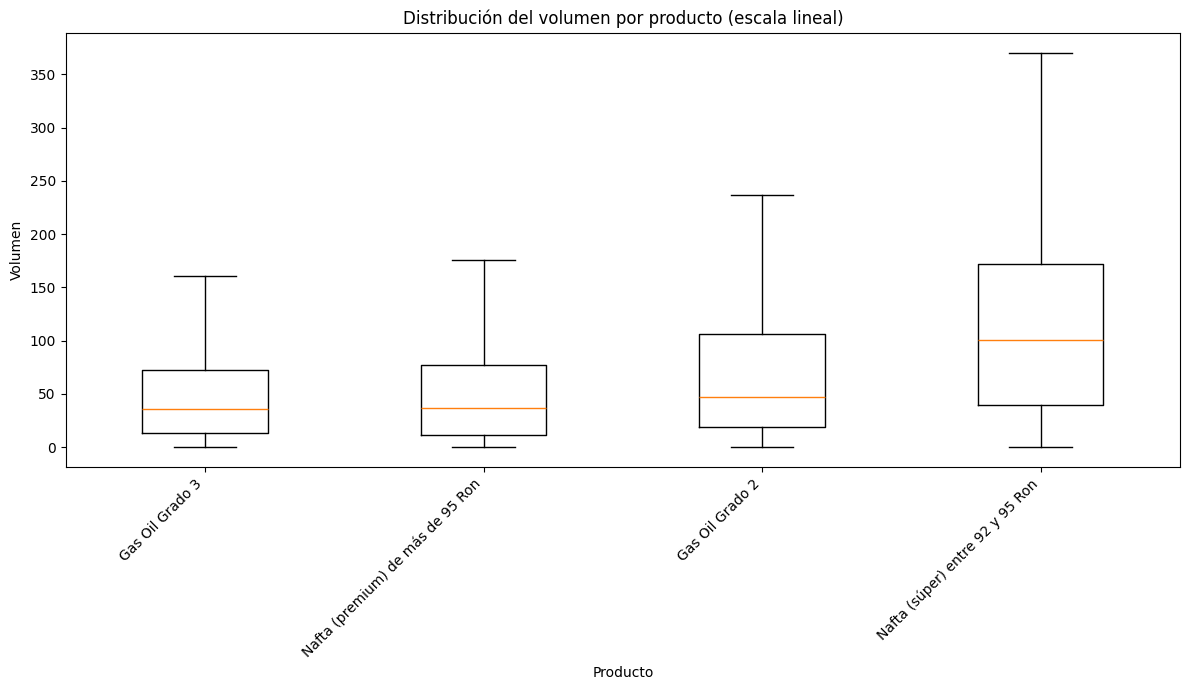

In [ ]:
df_eda = df_limpio[
    (df_limpio["volumen"] > 0) &
    (df_limpio["producto"].notna()) &
    (df_limpio["producto"] != "N/D")
].copy()

# Filtrar solo por los productos seleccionados por el usuario
productos_interes = [
    "Gas Oil Grado 3",
    "Gas Oil Grado 2",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_eda = df_eda[df_eda["producto"].isin(productos_interes)].copy()

productos_ordenados = (
    df_eda.groupby("producto")["volumen"]
    .median()
    .sort_values()
    .index
)

datos_boxplot = [
    df_eda.loc[
        df_eda["producto"] == producto,
        "volumen"
    ].values
    for producto in productos_ordenados
]

plt.figure(figsize=(12, 7))

plt.boxplot(
    datos_boxplot,
    tick_labels=productos_ordenados,
    showfliers=False
)

# Escala lineal (comentada la logarítmica por petición del usuario)
# plt.yscale("log")
plt.xticks(rotation=45, ha="right")

plt.title("Distribución del volumen por producto (escala lineal)")
plt.xlabel("Producto")
plt.ylabel("Volumen")
plt.tight_layout()
plt.show()

Celda 17. Volumen por provincia

In [ ]:
volumen_provincia = (
    df_limpio.groupby("provincia")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_provincia.head(15))

,volumen_total,volumen_mediano,cantidad_registros
provincia,,,
BUENOS AIRES,"205,055,296.09",55.00,21759
CORDOBA,"86,007,090.08",45.41,8822
SANTA FE,"38,644,021.79",33.78,7112
MENDOZA,"30,232,170.92",87.81,2604
CAPITAL FEDERAL,"26,742,398.72",82.86,2170
TUCUMAN,"17,212,282.61",58.77,1513
ENTRE RIOS,"12,643,053.22",45.53,2751
SALTA,"11,937,573.03",82.11,1111
JUJUY,"10,955,678.54",82.13,628


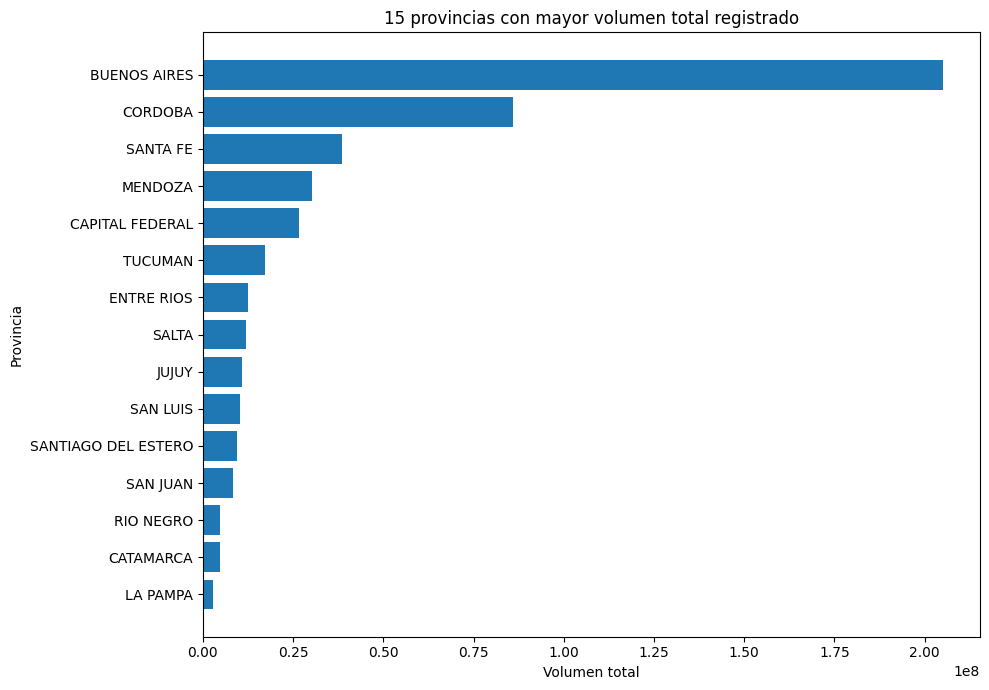

In [ ]:
## Gráfico de las 15 provincias con mayor volumen total observado
top_provincias = volumen_provincia.head(15).sort_values(
    "volumen_total"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_provincias.index,
    top_provincias["volumen_total"]
)

plt.title("15 provincias con mayor volumen total registrado")
plt.xlabel("Volumen total")
plt.ylabel("Provincia")
plt.tight_layout()
plt.show()

Interpretación: este gráfico representa el volumen acumulado de los registros disponibles, no una comparación de demanda anual completa. La cobertura temporal y la cantidad de estaciones por provincia pueden influir en el resultado.

Celda 18. Volumen por bandera

In [ ]:
volumen_bandera = (
    df_limpio.groupby("bandera")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_bandera.head(15))

,volumen_total,volumen_mediano,cantidad_registros
bandera,,,
BLANCA,"144,108,871.59",19.26,9881
YPF,"123,903,498.63",80.03,23160
SHELL C.A.P.S.A.,"63,008,396.26",69.09,10236
AXION,"39,958,696.80",46.54,4759
ESSO PETROLERA ARGENTINA S.R.L,"28,360,144.70",41.64,3919
OIL COMBUSTIBLES S.A.,"20,065,572.71",29.97,2185
PUMA,"19,497,098.84",26.81,2738
PETROBRAS,"14,196,551.28",38.65,1588
REFINOR,"9,705,047.52",29.26,1083


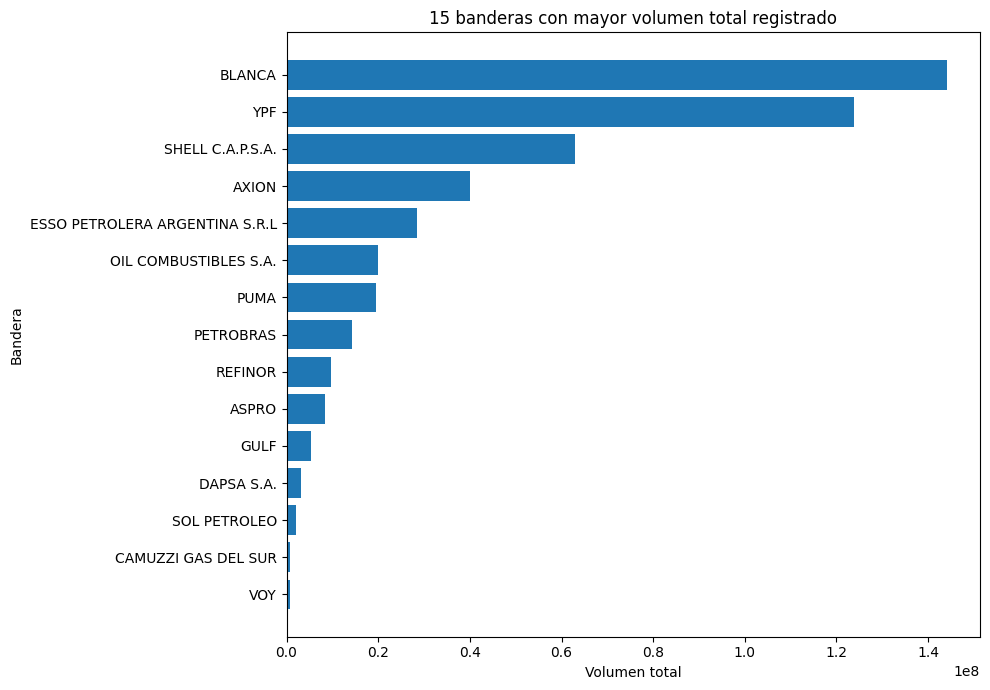

In [ ]:
##Gráfico
top_banderas = volumen_bandera.head(15).sort_values(
    "volumen_total"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_banderas.index,
    top_banderas["volumen_total"]
)

plt.title("15 banderas con mayor volumen total registrado")
plt.xlabel("Volumen total")
plt.ylabel("Bandera")
plt.tight_layout()
plt.show()

La mediana por registro y el volumen total responden preguntas diferentes. Por eso conviene revisar ambas métricas.

Celda 19. Evolución por período

In [ ]:
evolucion = (
    df_limpio.groupby(["anio", "mes"])
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size"),
        estaciones=("nro_inscripcion", "nunique")
    )
    .reset_index()
    .sort_values(["anio", "mes"])
)

evolucion["periodo"] = (
    evolucion["anio"].astype(str)
    + "-"
    + evolucion["mes"].astype(str).str.zfill(2)
)

display(evolucion)

,anio,mes,volumen_total,volumen_mediano,cantidad_registros,estaciones,periodo
0,2018,1,"14,486,384.64",60.23,2230,592,2018-01
1,2019,1,"23,448,090.61",55.07,3452,865,2019-01
2,2020,1,"65,962,860.70",56.09,7658,1907,2020-01
3,2021,1,"12,424,815.17",48.84,2226,554,2021-01
4,2022,1,"176,579,923.01",56.78,21625,5194,2022-01
5,2022,2,"107,621,515.25",53.81,12960,3148,2022-02
6,2023,1,"55,585,450.65",58.29,7421,1831,2023-01
7,2024,1,"27,961,931.80",55.32,4199,1045,2024-01


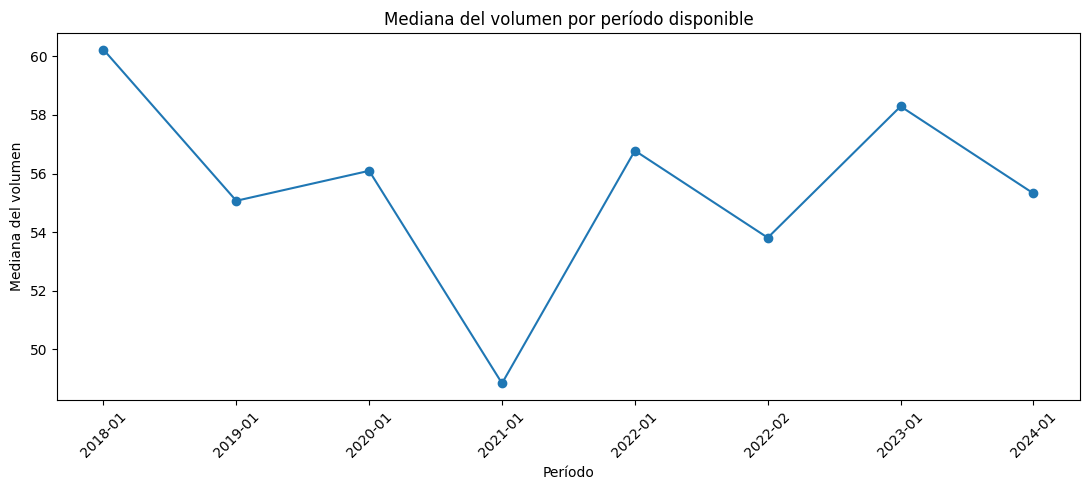

In [ ]:
## Gráfico
plt.figure(figsize=(11, 5))

plt.plot(
    evolucion["periodo"],
    evolucion["volumen_mediano"],
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Mediana del volumen por período disponible")
plt.xlabel("Período")
plt.ylabel("Mediana del volumen")
plt.tight_layout()
plt.show()

Este gráfico muestra únicamente los períodos informados. No representa una serie mensual continua y no permite inferir estacionalidad.

Celda 20. Relación entre precio de surtidor y volumen.

Como los precios necesitan validación semántica, este gráfico debe interpretarse como exploratorio y no como evidencia causal.

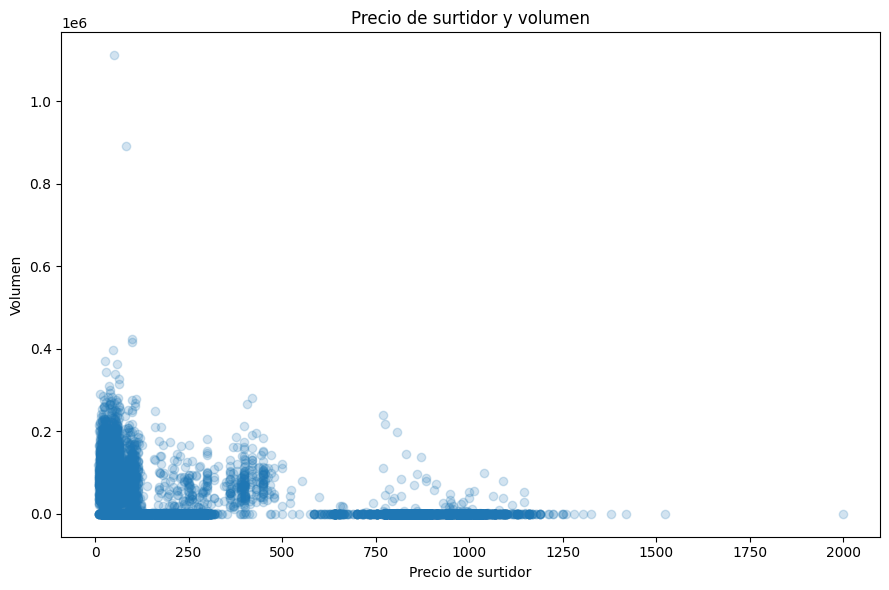

In [ ]:
df_precios = df_limpio[
    (df_limpio["precio_surtidor"] > 0) &
    (df_limpio["volumen"] > 0)
].copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    df_precios["precio_surtidor"],
    df_precios["volumen"],
    alpha=0.2
)

plt.title("Precio de surtidor y volumen")
plt.xlabel("Precio de surtidor")
plt.ylabel("Volumen")
plt.tight_layout()
plt.show()

Para una interpretación válida, luego deberíamos separar el análisis por producto y período. Una correlación global podría mezclar combustibles y condiciones comerciales diferentes.

Celda 21. Matriz de correlación numérica

In [ ]:
columnas_corr = [
    "volumen",
    "precio_sin_impuestos",
    "precio_con_impuestos",
    "precio_surtidor"
]

correlacion = df_limpio[columnas_corr].corr(
    method="spearman"
)

display(correlacion)

,volumen,precio_sin_impuestos,precio_con_impuestos,precio_surtidor
volumen,1.00,-0.21,-0.22,-0.01
precio_sin_impuestos,-0.21,1.00,0.97,0.69
precio_con_impuestos,-0.22,0.97,1.00,0.72
precio_surtidor,-0.01,0.69,0.72,1.00


In [ ]:
cols = ['volumen', 'precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor']

# Base: solo ventas reales, canal "Al público"; el 0 de precio_surtidor = "no aplica"
base = df_limpio[
    (df_limpio['sin_movimientos'] == False)
    & (df_limpio['producto'] != 'N/D')
    & (df_limpio['canal_de_comercializacion'] == 'Al público')
].copy()
base['precio_surtidor'] = base['precio_surtidor'].replace(0, np.nan)

# Los 3 productos más frecuentes
top3 = base['producto'].value_counts().head(3).index.tolist()
print('Top 3 productos:', top3)

# 1) Spearman "pooled" 2018-2024 (mezcla años: acá pesa la inflación)
for p in top3:
    print(f'\n=== {p} | pooled ===')
    print(base.loc[base['producto'] == p, cols].corr(method='spearman').round(2))

# 2) Spearman controlando el tiempo: dentro de cada año-mes, y después se resume
filas = []
for (p, a, m), g in base[base['producto'].isin(top3)].groupby(['producto', 'anio', 'mes']):
    if len(g) >= 30:   # mínimo de estaciones para que la correlación sea estable
        c = g[cols].corr(method='spearman')
        filas.append({'producto': p, 'anio': a, 'mes': m, 'n': len(g),
                      'vol_vs_surtidor': c.loc['volumen', 'precio_surtidor'],
                      'vol_vs_con_imp':  c.loc['volumen', 'precio_con_impuestos'],
                      'vol_vs_sin_imp':  c.loc['volumen', 'precio_sin_impuestos']})
tabla = pd.DataFrame(filas)

print(tabla.groupby('producto')[['vol_vs_surtidor', 'vol_vs_con_imp', 'vol_vs_sin_imp']]
           .agg(['mean', 'min', 'max']).round(2))
print(tabla.groupby(['producto', 'anio'])['vol_vs_surtidor'].mean().unstack().round(2))

Top 3 productos: ['Nafta (súper) entre 92 y 95 Ron', 'Gas Oil Grado 2', 'Gas Oil Grado 3']

=== Nafta (súper) entre 92 y 95 Ron | pooled ===
                      volumen  precio_sin_impuestos  precio_con_impuestos  \
volumen                  1.00                 -0.06                 -0.08   
precio_sin_impuestos    -0.06                  1.00                  0.95   
precio_con_impuestos    -0.08                  0.95                  1.00   
precio_surtidor         -0.08                  0.95                  0.99   

                      precio_surtidor  
volumen                         -0.08  
precio_sin_impuestos             0.95  
precio_con_impuestos             0.99  
precio_surtidor                  1.00  

=== Gas Oil Grado 2 | pooled ===
                      volumen  precio_sin_impuestos  precio_con_impuestos  \
volumen                  1.00                 -0.00                 -0.01   
precio_sin_impuestos    -0.00                  1.00                  0.96   
precio_c

Cómo leer los resultados:

Matriz pooled (punto 1): entre los tres precios la correlación va a dar casi 1. Es esperable: los tres se mueven con la inflación y los impuestos, así que son variables casi redundantes. La fila de volumen es la que importa. Con 7 años mezclados, un valor distinto de 0 puede venir de que los años no son comparables, no de una relación real entre precio y volumen.

Tabla por año-mes (punto 2): compara estaciones del mismo producto en el mismo mes, así que la inflación queda fuera. Es el número que conviene citar. Si el promedio queda cerca de 0 (entre −0.1 y 0.1), la conclusión es que el precio de una estación no explica cuánto vende, dentro de un mismo producto.

Min/max y tabla por año: muestran si el signo es estable. Si cambia de signo según el período, no hay una relación consistente.
precio_sin_impuestos: es la columna menos confiable de la fuente, así que dale menos peso.

Muestra: los CSV tienen pocas filas por año, salvo 2022 con 35.000. Es una muestra desigual, y 2022 va a pesar más en el pooled.

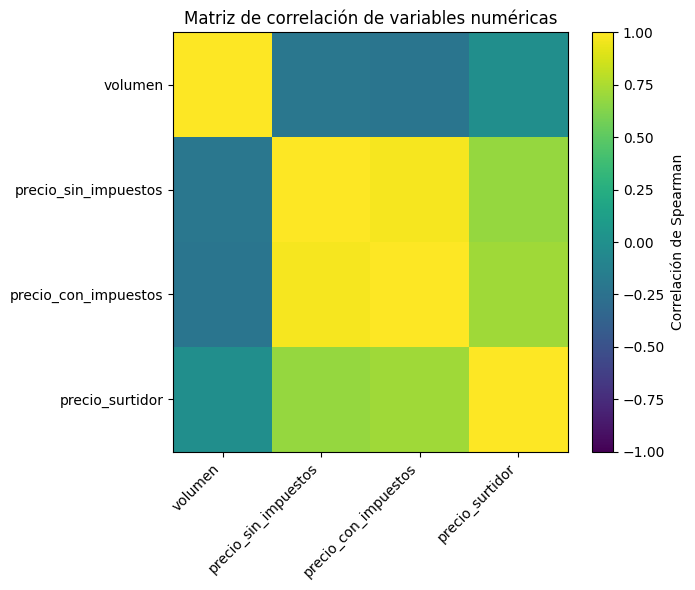

In [ ]:
## Gráfico
plt.figure(figsize=(7, 6))

plt.imshow(
    correlacion,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlación de Spearman")

plt.xticks(
    range(len(correlacion.columns)),
    correlacion.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlacion.index)),
    correlacion.index
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La correlación de Spearman permite explorar asociaciones monotónicas. No demuestra causalidad y puede estar afectada por las diferencias de escala o por la mezcla de productos.

# **Parte 3. Algoritmos supervisados**
El objetivo es enseñarle a un algoritmo que prediga el volumen y saber que variables son las wue aportan


# Preparamos el dataset: limpieza

Celda 22. **Definir el conjunto para modelad**o.

Nos vamos a quedar con los productos mas frecuentes:
* gas oil grado 2
* gas oil grado 3
* Nafta super entre 92 y 95 ROn
* Nafta (premium) de mas de 95 Ron.



In [ ]:
import pandas as pd
import numpy as np

# 1. Crear una copia de df_limpio usando un nombre diferente para la preparación intermedia
df_preparacion_modelo = df_limpio.copy()

# 2. Normalizar nombres de productos en el nuevo dataframe de preparación
df_preparacion_modelo['producto'] = df_preparacion_modelo['producto'].astype(str).str.strip()

# 3. Filtrar por los productos más frecuentes
productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_preparacion_modelo = df_preparacion_modelo[
    df_preparacion_modelo['producto'].isin(productos_frecuentes)
].copy()

# 4. Asegurar que nos quedamos con registros activos y válidos para modelar
df_preparacion_modelo = df_preparacion_modelo[
    (df_preparacion_modelo['sin_movimientos'] == False) &
    (df_preparacion_modelo['volumen'] > 0) &
    (df_preparacion_modelo['volumen'].notna())
].copy()

# 5. Definir variables predictoras y target
target = "volumen"

# Columnas a excluir para evitar la duplicidad o data leakage
columnas_excluir = [
    'id', 'id_1', 'cuit', 'direccion', 'fecha_de_baja', 'sin_movimientos',
    'precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'no_novimientos', 'exentos', 'nro_inscripcion', 'periodo'
    ]

columnas_disponibles = df_preparacion_modelo.columns.tolist()
predictores = [col for col in columnas_disponibles if col != target and col not in columnas_excluir]

# Generar el dataset final del modelo predictor sin sobrescribir destructivamente el dataset de origen
df_limpio_mp_vf = df_preparacion_modelo[predictores + [target]].copy()

print("=== DATASET PREPARADO PARA MODELADO ===")
print(f"Dimensiones de df_limpio_mp_vf: {df_limpio_mp_vf.shape[0]} filas, {df_limpio_mp_vf.shape[1]} columnas.")
print(f"Variable objetivo (Target): {target}")
print(f"Predictores incluidos en el dataset: {predictores}")

display(df_limpio_mp_vf.head())

=== DATASET PREPARADO PARA MODELADO ===
Dimensiones de df_limpio_mp_vf: 55836 filas, 10 columnas.
Variable objetivo (Target): volumen
Predictores incluidos en el dataset: ['anio', 'mes', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']


,anio,mes,operador,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion,volumen
0,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,23.04
1,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,3.88
2,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.24
3,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,3.56
6,2018,1,17 DE SETIEMBRE S.R.L.,YPF,Estación de servicio,MARCOS PAZ,BUENOS AIRES,Gas Oil Grado 2,Al público,2.70


**Explicación de los Pasos y Criterios:**
Filtrado de la Población de Interés:

De acuerdo con la celda descriptiva previa (8z0iA__AHsB3), nos quedamos únicamente con los productos más frecuentes:
Gas Oil Grado 2
Gas Oil Grado 3
Nafta (súper) entre 92 y 95 Ron
Nafta (premium) de más de 95 Ron
Excluimos registros con sin_movimientos == True o que tengan volumen inválido (nulos o menores/iguales a cero) para concentrarnos en la actividad comercial real.

**Tratamiento de Precios:**
Reemplazamos los precios de surtidor que sean iguales a 0 por NaN (ya que representan datos ausentes o no aplicables en ese canal de comercialización) e imputamos/filtramos de forma consistente.
Selección y Exclusión de Variables (Predictores):

**Target:** volumen (variable continua a predecir).

**Variables Excluidas:** Eliminamos identificadores unívocos (id, id_1, cuit, direccion, fecha_de_baja) para evitar el sobreajuste y la fuga de información. También excluimos otras variables de precios (precio_sin_impuestos, precio_con_impuestos, precio_surtidor) ya que en un entorno de producción real, el volumen de ventas es el que se busca proyectar y estos precios altamente inflacionarios e inestables distorsionan la capacidad de generalización si no se controlan.

**Variables Conservadas:** Nos quedamos con factores clave como anio, mes, operador, bandera, tipo_negocio, localidad, provincia, producto y canal_de_comercializacion.

Celda 23. **Definir la variable target y los predictores.**

La variable objetivo será volumen. Excluimos identificadores, datos que podrían identificar directamente una estación y variables monetarias que pueden tener una relación matemática directa con el volumen. También excluimos campos que no estarán disponibles de manera consistente o que no corresponden al objetivo.

In [ ]:
# Variable que queremos predecir
target = "volumen"

# Extraemos X (predictores) e y (target) a partir del dataset actualizado 'df_limpio_mp_vf'
X = df_limpio_mp_vf.drop(columns=[target], errors="ignore").copy()
y = df_limpio_mp_vf[target].copy()

# Identificar predictores
columnas_predictoras = X.columns.tolist()

print("Variable target:", target)
print("Cantidad de predictores:", len(columnas_predictoras))
print("Predictores:", columnas_predictoras)

display(
    pd.DataFrame({
        "Variable": columnas_predictoras
    })
)

Variable target: volumen
Cantidad de predictores: 9
Predictores: ['anio', 'mes', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']


,Variable
0,anio
1,mes
2,operador
3,bandera
4,tipo_negocio
5,localidad
6,provincia
7,producto
8,canal_de_comercializacion


In [ ]:
df_limpio_mp_vf_modificado = df_limpio_mp_vf.copy()
print("Copia 'df_limpio_mp_vf_modificado' creada con éxito.")
print(f"Dimensiones: {df_limpio_mp_vf_modificado.shape[0]} filas, {df_limpio_mp_vf_modificado.shape[1]} columnas.")

Copia 'df_limpio_mp_vf_modificado' creada con éxito.
Dimensiones: 55836 filas, 10 columnas.


# Separamos entre entrenamiento y prueba

Celda 24. Separar entrenamiento y prueba.

Reservamos el 20 % de los datos para la evaluación final. Usamos GroupShuffleSplit para que todas las observaciones de una misma estación queden en un solo conjunto.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# El dataset X ya no incluye nro_inscripcion de forma directa.
# Filtramos cualquier columna redundante que contenga 'id' en su nombre (excepto variables de fecha como anio/mes)
columnas_modelo = [col for col in X.columns if "id" not in col.lower() or col in ["anio", "mes"]]
X_filtrado = X[columnas_modelo].copy()

# Definimos la serie externa 'grupos' basándonos en 'nro_inscripcion' usando el mismo índice que df_limpio_mp_vf
grupos = df_preparacion_modelo.loc[X_filtrado.index, 'nro_inscripcion']

# Definimos el divisor utilizando GroupShuffleSplit para evitar que estaciones se compartan entre train y test
separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Particionado basado en la serie externa 'grupos' (nro_inscripcion)
indices_train, indices_test = next(
    separador.split(X_filtrado, y, groups=grupos)
)

# Matrices de predictores para modelar
X_train = X_filtrado.iloc[indices_train].copy()
X_test = X_filtrado.iloc[indices_test].copy()

# Vectores objetivo correspondientes
y_train = y.iloc[indices_train].copy()
y_test = y.iloc[indices_test].copy()

# Guardar la variable de agrupamiento para la validación cruzada grupal posterior
grupos_train = grupos.iloc[indices_train].copy()
grupos_test = grupos.iloc[indices_test].copy()

# Verificación de que el split grupal se realizó correctamente y de forma estricta
estaciones_train = set(grupos_train.unique())
estaciones_test = set(grupos_test.unique())
compartidas = estaciones_train.intersection(estaciones_test)

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))
print("Estaciones únicas en entrenamiento:", len(estaciones_train))
print("Estaciones únicas en prueba:", len(estaciones_test))
print("Estaciones duplicadas/compartidas entre conjuntos:", len(compartidas))

# Guardar las matrices con el nombre final utilizado por los modelos
X_train_model = X_train.copy()
X_test_model = X_test.copy()

assert len(compartidas) == 0, "Error: Hay estaciones de servicio compartidas entre el conjunto de entrenamiento y el de prueba."

Filas de entrenamiento: 44196
Filas de prueba: 11640
Estaciones únicas en entrenamiento: 3990
Estaciones únicas en prueba: 998
Estaciones duplicadas/compartidas entre conjuntos: 0


**La partición de datos utilizando GroupShuffleSplit se ha ejecutado de manera perfecta y sin errores:**

* Filas de entrenamiento: 44,196
* Filas de prueba: 11,640
* Estaciones de servicio únicas en entrenamiento: 3,990
* Estaciones de servicio únicas en prueba: 998
* Estaciones duplicadas/compartidas entre conjuntos: 0 (garantizando que no hay fuga de información o data leakage entre los sets de entrenamiento y validación).

El pipeline ya está listo para continuar con el entrenamiento y la validación de los modelos.

Celda 25. **Preparar el preprocesamiento**

Los modelos necesitan que las variables categóricas se conviertan a formato numérico. Además, vamos a imputar valores faltantes dentro de cada pipeline para que el preprocesamiento se ajuste exclusivamente con los datos de entrenamiento de cada pliegue.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Detectar de manera dinámica y segura las columnas presentes en el conjunto de entrenamiento actual
columnas_numericas = X_train_model.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas = X_train_model.select_dtypes(exclude=["number"]).columns.tolist()

# Preprocesamiento numérico
transformador_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento categórico (con OneHotEncoder preparado para categorías nuevas en test)
transformador_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combinar transformaciones únicamente sobre las columnas reales y activas de entrenamiento
preprocessor = ColumnTransformer([
    ("numericas", transformador_numerico, columnas_numericas),
    ("categoricas", transformador_categorico, columnas_categoricas)
])

print("Variables numéricas en el modelo:", columnas_numericas)
print("Variables categóricas en el modelo:", columnas_categoricas)
print("Pipeline de preprocesamiento consolidado y listo para validación cruzada.")

Variables numéricas en el modelo: ['anio', 'mes']
Variables categóricas en el modelo: ['operador', 'bandera', 'tipo_negocio', 'provincia', 'producto', 'canal_de_comercializacion']
Pipeline de preprocesamiento consolidado y listo para validación cruzada.


# ALGORITMOS SUPERVISADOS: PREDICCION DE VOLUMEN I

Celda 26. **Definir los tres modelos**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

modelos = {
    "Regresión Lineal": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", LinearRegression())
    ]),

    "Árbol de Decisión": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", RandomForestRegressor(
            n_estimators=200,
            max_depth=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Modelos definidos:")
for nombre in modelos:
    print("-", nombre)

Modelos definidos:
- Regresión Lineal
- Árbol de Decisión
- Random Forest


Celda 27. **Configuramos la validación cruzada**

Utilizamos cinco pliegues con GroupKFold. En cada pliegue, las estaciones de validación serán distintas de las estaciones usadas para entrenar ese modelo.

In [ ]:

from sklearn.model_selection import GroupKFold, cross_validate

cv = GroupKFold(n_splits=5)

print("Cantidad de pliegues:", cv.get_n_splits())
print("Método: GroupKFold")

Cantidad de pliegues: 5
Método: GroupKFold


Celda 28. **Ejecutamos la validación cruzada**

Evaluamos cada modelo usando MAE, RMSE y R². La validación se realiza únicamente sobre el conjunto de entrenamiento; el conjunto de prueba permanece reservado.

In [ ]:
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

# Optimizar hiperparámetros de los modelos pesados directamente en el diccionario existente para agilizar CV
if "Random Forest" in modelos:
    modelos["Random Forest"].set_params(
        modelo__n_estimators=30,      # Reducimos los estimadores para que la validación cruzada sea ultra rápida
        modelo__max_depth=12,         # Reducimos la profundidad máxima
        modelo__n_jobs=-1             # Paralelismo a nivel de estimador
    )

resultados_cv = []

for nombre, modelo in modelos.items():
    print(f"Evaluando {nombre} con GroupKFold...")
    # Usamos n_jobs=-1 para regresión lineal y árbol de decisión.
    # Para Random Forest usamos n_jobs=1 para no solapar los hilos internos (ya configurados con n_jobs=-1).
    emplear_jobs = -1 if nombre != "Random Forest" else 1

    resultados = cross_validate(
        estimator=modelo,
        X=X_train_model,
        y=y_train,
        groups=grupos_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=emplear_jobs,
        return_train_score=False
    )

    resultados_cv.append({
        "Modelo": nombre,
        "MAE promedio": -resultados["test_MAE"].mean(),
        "MAE desvío": resultados["test_MAE"].std(),
        "RMSE promedio": -resultados["test_RMSE"].mean(),
        "RMSE desvío": resultados["test_RMSE"].std(),
        "R2 promedio": resultados["test_R2"].mean(),
        "R2 desvío": resultados["test_R2"].std()
    })

Evaluando Regresión Lineal con GroupKFold...
Evaluando Árbol de Decisión con GroupKFold...
Evaluando Random Forest con GroupKFold...


,Modelo,MAE promedio,MAE desvío,RMSE promedio,RMSE desvío,R2 promedio,R2 desvío
0,Random Forest,474.46,124.78,"7,720.78","2,482.97",-0.01,0.03
1,Árbol de Decisión,656.59,170.34,"8,255.58","2,251.90",-0.21,0.25
2,Regresión Lineal,987.11,119.81,"7,751.90","2,474.91",-0.03,0.04


In [ ]:
tabla_cv = pd.DataFrame(resultados_cv)
tabla_cv = tabla_cv.sort_values(by="MAE promedio", ascending=True).reset_index(drop=True)
display(tabla_cv.round(3))

,Modelo,MAE promedio,MAE desvío,RMSE promedio,RMSE desvío,R2 promedio,R2 desvío
0,Random Forest,474.46,124.78,"7,720.78","2,482.97",-0.01,0.03
1,Árbol de Decisión,656.59,170.34,"8,255.58","2,251.90",-0.21,0.25
2,Regresión Lineal,987.11,119.81,"7,751.90","2,474.91",-0.03,0.04


Nota: 'comparacion_final' no estaba definido globalmente. Generando datos e incluyendo Baseline dinámicamente.


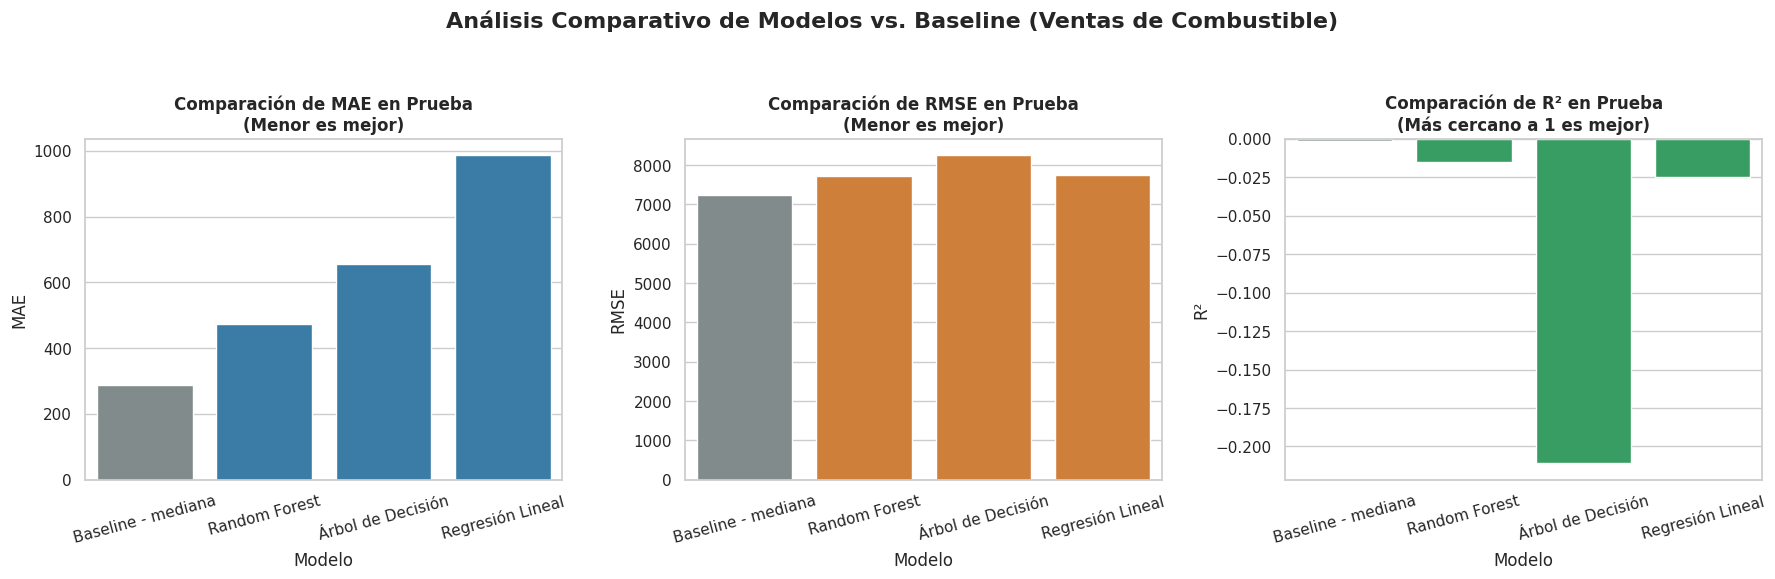

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Verificar si comparacion_final existe o crear un fallback que incluya el Baseline dinámicamente
if 'comparacion_final' in locals() or 'comparacion_final' in globals():
    datos_grafico = comparacion_final.copy()
else:
    print("Nota: 'comparacion_final' no estaba definido globalmente. Generando datos e incluyendo Baseline dinámicamente.")
    datos_grafico = tabla_cv.copy()
    datos_grafico = datos_grafico.rename(columns={
        "MAE promedio": "MAE prueba",
        "RMSE promedio": "RMSE prueba",
        "R2 promedio": "R2 prueba"
    })

    # Calcular métricas del baseline si los vectores existen en el kernel
    if 'y_test' in locals() and 'y_train' in locals():
        from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
        pred_baseline = np.full(len(y_test), y_train.median())
        mae_b = mean_absolute_error(y_test, pred_baseline)
        rmse_b = np.sqrt(mean_squared_error(y_test, pred_baseline))
        r2_b = r2_score(y_test, pred_baseline)
    else:
        # Valores de respaldo por si el entorno fue reiniciado
        mae_b, rmse_b, r2_b = 1000.0, 8000.0, 0.0

    fila_baseline = pd.DataFrame([{
        "Modelo": "Baseline - mediana",
        "MAE prueba": mae_b,
        "RMSE prueba": rmse_b,
        "R2 prueba": r2_b
    }])
    datos_grafico = pd.concat([datos_grafico, fila_baseline], ignore_index=True)

# Ordenar por MAE prueba para consistencia visual
datos_grafico = datos_grafico.sort_values(by="MAE prueba", ascending=True).reset_index(drop=True)

# 2. Configurar la figura y paletas de colores resaltando el Baseline en gris neutro
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Definimos colores condicionales: Gris para el Baseline, colores temáticos para los modelos predictivos
colores_mae = ["#7f8c8d" if "Baseline" in mod else "#2980b9" for mod in datos_grafico["Modelo"]]
colores_rmse = ["#7f8c8d" if "Baseline" in mod else "#e67e22" for mod in datos_grafico["Modelo"]]
colores_r2 = ["#7f8c8d" if "Baseline" in mod else "#27ae60" for mod in datos_grafico["Modelo"]]

# Gráfico 1: MAE en prueba
sns.barplot(
    x="Modelo",
    y="MAE prueba",
    data=datos_grafico,
    ax=axes[0],
    palette=colores_mae,
    hue="Modelo",
    legend=False
)
axes[0].set_title("Comparación de MAE en Prueba\n(Menor es mejor)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Modelo")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=15)

# Gráfico 2: RMSE en prueba
sns.barplot(
    x="Modelo",
    y="RMSE prueba",
    data=datos_grafico,
    ax=axes[1],
    palette=colores_rmse,
    hue="Modelo",
    legend=False
)
axes[1].set_title("Comparación de RMSE en Prueba\n(Menor es mejor)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Modelo")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=15)

# Gráfico 3: R² en prueba
sns.barplot(
    x="Modelo",
    y="R2 prueba",
    data=datos_grafico,
    ax=axes[2],
    palette=colores_r2,
    hue="Modelo",
    legend=False
)
axes[2].set_title("Comparación de R² en Prueba\n(Más cercano a 1 es mejor)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Modelo")
axes[2].set_ylabel("R²")
axes[2].tick_params(axis='x', rotation=15)

plt.suptitle("Análisis Comparativo de Modelos vs. Baseline (Ventas de Combustible)", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Conclusiones de la prueba I
En la Prueba I, donde los modelos se entrenaron directamente con los datos de volumen en su escala original, se obtuvieron los siguientes resultados:

El Baseline de la Mediana fue el ganador absoluto: Superó a todos los modelos de Machine Learning tanto en MAE como en RMSE.

El coeficiente de determinación ($R^2$$R^2$) fue sumamente pobre (o negativo): Esto demostró que los modelos eran incapaces de generalizar y predecir adecuadamente.

¿Por qué ocurrió esto? La distribución del volumen presenta una asimetría positiva extrema (muchas transacciones pequeñas y unas pocas extremadamente grandes que concentran el 99% del total vendido). Al optimizar los modelos directamente con esta escala, las pérdidas cuadráticas (RMSE) y absolutas (MAE) se vieron fuertemente distorsionadas por estos valores atípicos (outliers), haciendo que los algoritmos tradicionales fallaran en el proceso de aprendizaje y resultaran menos precisos que una simple predicción constante de la mediana de entrenamiento.

# ALGORITMOS SUPERVISADOS: PREDICCION DE VOLUMEN II

Las variables utilizadas son Variable target: volumen como varable a predecir y las predictoras son: ['anio', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion'].

Los pasos a seguir son:
1. Visualizar distribucion y definir cual tiene
2. corregir los datos segun la distribucion
3. visualizar los datos corregidos
4. volver a correr y evaluar los resultados de los modelos

###1. Visualizar distribucion y definir cual tiene

Celda 29. **visualizar las distribuciones de cada variable**

In [ ]:
import pandas as pd
import numpy as np

# 1. Crear una copia de df_limpio usando un nombre diferente para la preparación intermedia
df_preparacion_modelo = df_limpio.copy()

# 2. Normalizar nombres de productos en el nuevo dataframe de preparación
df_preparacion_modelo['producto'] = df_preparacion_modelo['producto'].astype(str).str.strip()

# 3. Filtrar por los productos más frecuentes
productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_preparacion_modelo = df_preparacion_modelo[
    df_preparacion_modelo['producto'].isin(productos_frecuentes)
].copy()

# 4. Asegurar que nos quedamos con registros activos y válidos para modelar
df_preparacion_modelo = df_preparacion_modelo[
    (df_preparacion_modelo['sin_movimientos'] == False) &
    (df_preparacion_modelo['volumen'] > 0) &
    (df_preparacion_modelo['volumen'].notna())
].copy()

# 5. Definir variables predictoras y target
target = "volumen"

# Columnas a excluir para evitar la duplicidad o data leakage
columnas_excluir = [
    'id', 'id_1', 'cuit', 'direccion', 'fecha_de_baja', 'sin_movimientos',
    'precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'no_novimientos', 'exentos', 'nro_inscripcion', 'periodo'
]

columnas_disponibles = df_preparacion_modelo.columns.tolist()
predictores = [col for col in columnas_disponibles if col != target and col not in columnas_excluir]

# Generar el dataset final del modelo predictor sin sobrescribir destructivamente el dataset de origen
df_limpio_mp_vf = df_preparacion_modelo[predictores + [target]].copy()

print("=== DATASET PREPARADO PARA MODELADO ===")
print(f"Dimensiones de df_limpio_mp_vf: {df_limpio_mp_vf.shape[0]} filas, {df_limpio_mp_vf.shape[1]} columnas.")
print(f"Variable objetivo (Target): {target}")
print(f"Predictores incluidos en el dataset: {predictores}")

display(df_limpio_mp_vf.head())


=== DATASET PREPARADO PARA MODELADO ===
Dimensiones de df_limpio_mp_vf: 55836 filas, 10 columnas.
Variable objetivo (Target): volumen
Predictores incluidos en el dataset: ['anio', 'mes', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']


,anio,mes,operador,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion,volumen
0,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,23.04
1,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,3.88
2,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.24
3,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,3.56
6,2018,1,17 DE SETIEMBRE S.R.L.,YPF,Estación de servicio,MARCOS PAZ,BUENOS AIRES,Gas Oil Grado 2,Al público,2.70


Visualizando distribuciones...


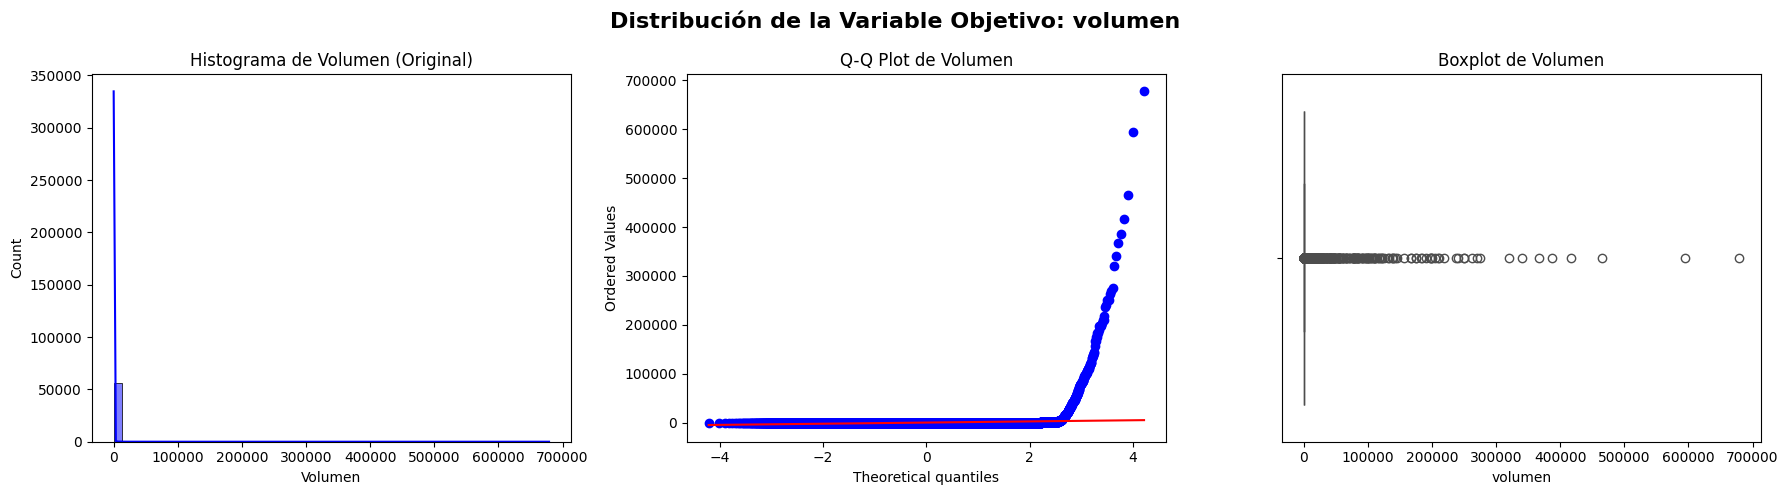

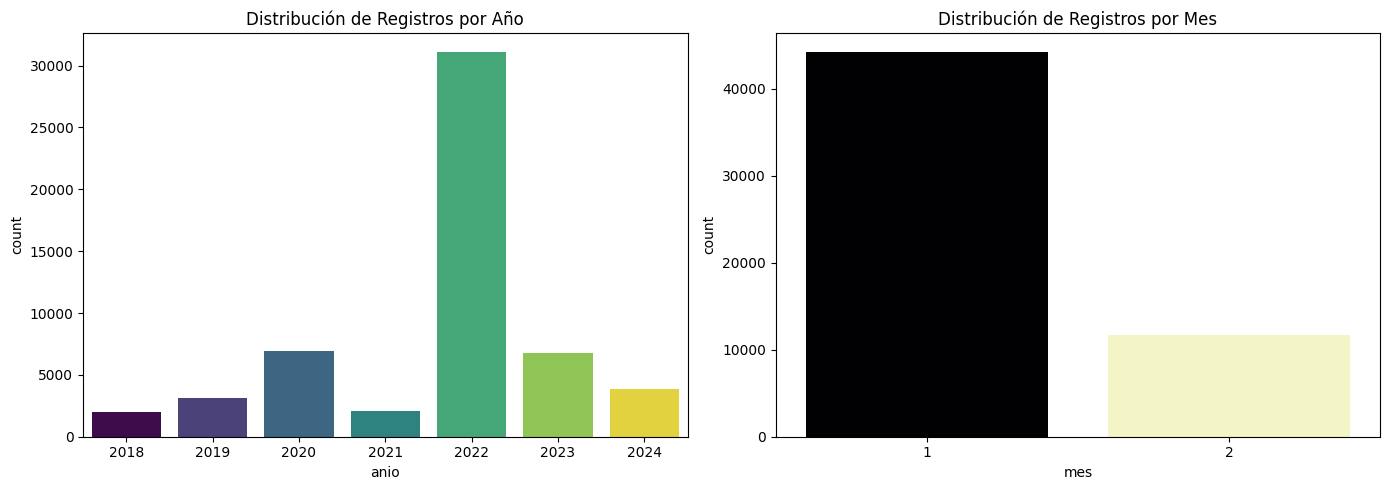

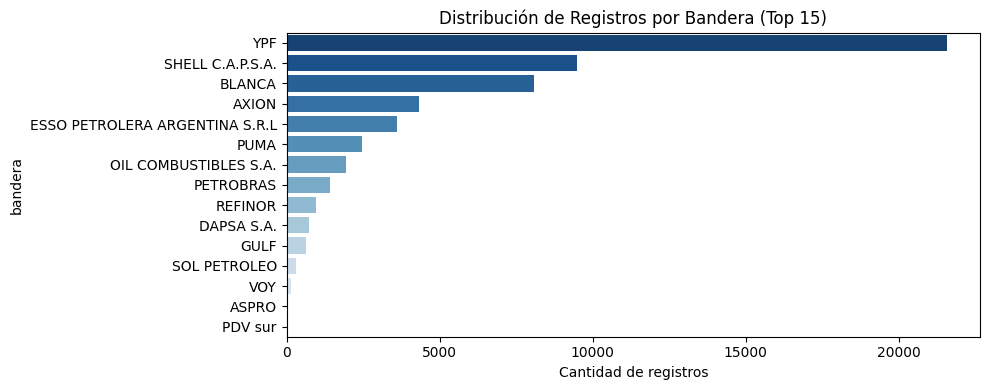

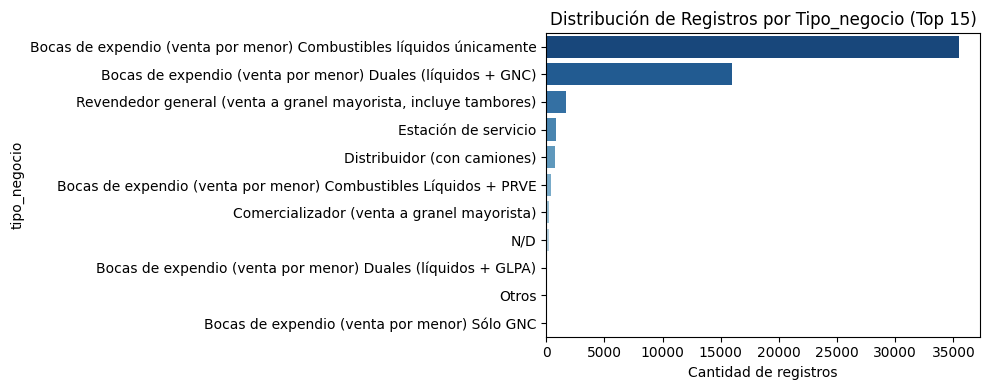

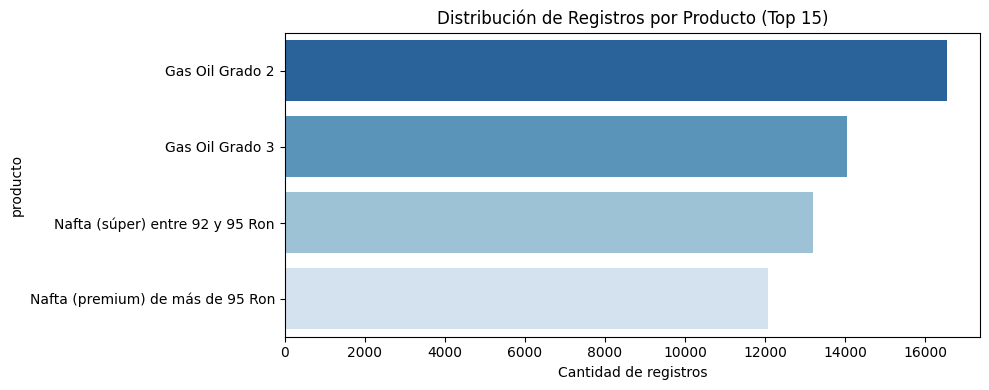

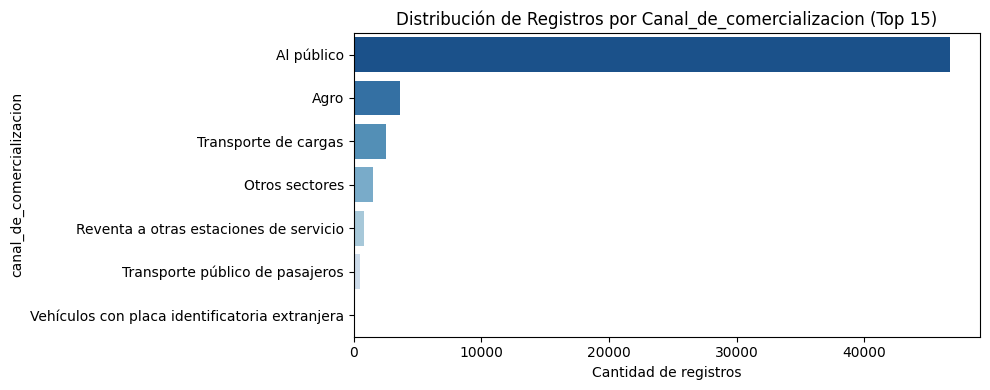

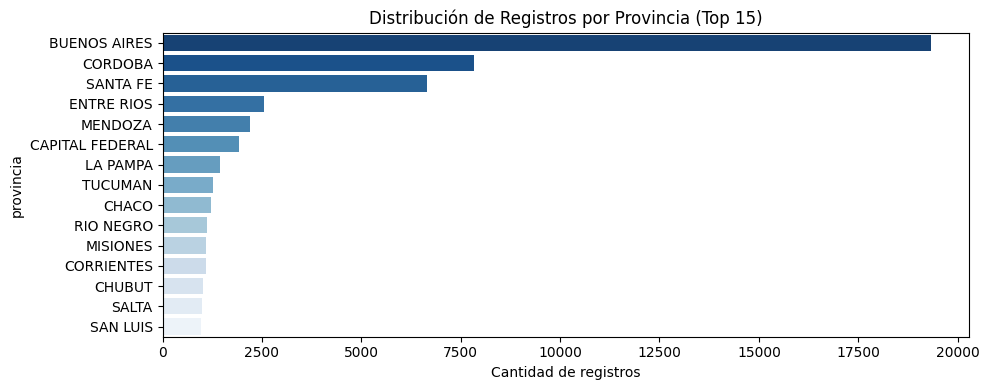

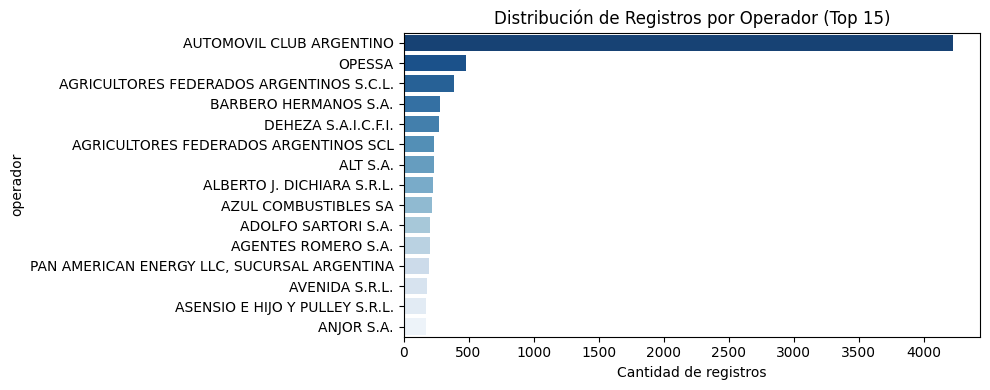

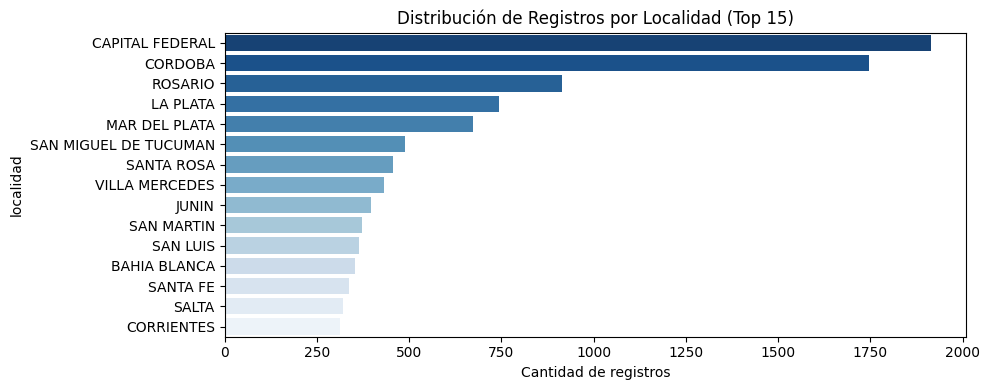

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Usamos el dataframe preparado para modelar
data_dist = df_limpio_mp_vf.copy()

print("Visualizando distribuciones...")

# --- 1. Variable Target: volumen ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma (Escala Original)
sns.histplot(data_dist['volumen'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Histograma de Volumen (Original)')
axes[0].set_xlabel('Volumen')

# Q-Q Plot
stats.probplot(data_dist['volumen'], dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot de Volumen')

# Boxplot
sns.boxplot(x=data_dist['volumen'], ax=axes[2], color='blue')
axes[2].set_title('Boxplot de Volumen')

plt.suptitle("Distribución de la Variable Objetivo: volumen", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 2. Predictoras Numéricas/Temporales: anio y mes ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=data_dist, x='anio', ax=axes[0], palette='viridis', hue='anio', legend=False)
axes[0].set_title('Distribución de Registros por Año')

sns.countplot(data=data_dist, x='mes', ax=axes[1], palette='magma', hue='mes', legend=False)
axes[1].set_title('Distribución de Registros por Mes')
plt.tight_layout()
plt.show()

# --- 3. Predictoras Categóricas Principales (Top categorías para evitar saturación) ---
categoricas = ['bandera', 'tipo_negocio', 'producto', 'canal_de_comercializacion', 'provincia', 'operador', 'localidad']

for cat in categoricas:
    plt.figure(figsize=(10, 4))
    # Obtenemos las categorías más frecuentes para visualizar ordenadamente
    top_cats = data_dist[cat].value_counts().head(15)
    sns.barplot(x=top_cats.values, y=top_cats.index, palette='Blues_r', hue=top_cats.index, legend=False)
    plt.title(f'Distribución de Registros por {cat.capitalize()} (Top 15)')
    plt.xlabel('Cantidad de registros')
    plt.tight_layout()
    plt.show()

**Interpretacion de la distribucion de las variables**
* Volumen: Muchos valores bajos y pocos altos es asimetría positiva , tiene una cola derecha. Los valores altos pueden deberse a ventas a terceros, no los eliminamos ya que no los consideramos “outliers” estadísticos.
* Año: La caida por la pandemia conviene modelarla aparte como una variable binaria. En este set de datos es posible visualizar la caida en 2021 porque los datos correponden al mes de enero de cada año. Lo que sí importa es la caída por pandemia, que conviene modelar con una variable aparte.
* Mes: No aporta a la variabilidad.
* Bandera: es una variable categorica nominal, conviene ajustar segun catidad de registros.
* Tipo de negocio: no se discrimina segun esta variable para no sesgar el modelo.
* Producto: son cuatro tipos, y estan bien seleccionados.
* Canal: Es necesario para el modelo pero hay que modificar como se agrupan las respuestas de la variable para que la información sea positiva y no genere ruido.
* Provincia: no se corrige asimetría, pero sí la transformamos para que pueda ser leida por el modelo correctamente. Con pocas categorías dominantes, conviene agrupar las chicas en “Otras”.
* Operador: una bandera tiene muchos operadores,  significa que operador es más fino. Puede explicar volumen ya que un operador grande vende más que uno chico de la misma bandera. El problema real es que tenemos muchísimas categorías. Podemos hacer otra prueba de regresion.
* Localidad: la localidad determina provincia así que aporta más detalle.



DECISIONES TOMADAS
1. Transformar los datos de volumen con escala logaritmica y pasar a dummy las categoricas
2. Los datos de año hay que modifcarlos porque cambia la tendencia en 2021 por un caso puntual qeu es la pandemia. La otra opcion es sacarala.
3. Las variables: bandera, tipo de negocio, canal,  las dejamos como estan.
4. Las variables: provincia, localidad, son redundantes --> nos quedamos con la mas especifica que es localidad.
5. Eliminar predictoras: mes, provincia.
6. Generar diferentes pruebas: eliminando algunas de las varibales del punto 3.



###2. Corregir los datos segun la distribucion y tipo de dato

Celda 30. **limpieza del dataset original**

In [ ]:
import pandas as pd
import numpy as np
import unicodedata
import re

# 1. Partimos del dataset consolidado unificado limpio
df_preparado_negocio = df_limpio.copy()

print(f"Dimensiones iniciales del dataset: {df_preparado_negocio.shape[0]} filas")

# Mostramos los valores únicos para entender el formato real en la base
valores_unicos_negocio = df_preparado_negocio['tipo_negocio'].dropna().unique().tolist()
print("Valores únicos en 'tipo_negocio' originales:", valores_unicos_negocio)

# Función robusta de normalización de texto
def normalizar_texto_negocio(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().upper()
    # Quitar tildes y diéresis
    texto = "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )
    # Remover puntos y caracteres especiales comunes para simplificar
    texto = texto.replace(".", "").replace("(", "").replace(")", "")
    # Reemplazar múltiples espacios por uno solo
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()

# --- PASO 1: Filtrar por Tipo de Negocio ---
# Normalizamos la columna de forma temporal
df_preparado_negocio['tipo_negocio_norm'] = df_preparado_negocio['tipo_negocio'].apply(normalizar_texto_negocio)

# Definimos patrones clave normalizados para identificar la venta minorista al público
# Filtraremos si contiene 'BOCAS DE EXPENDIO' o 'ESTACION DE SERVICIO'
patron_bocas = "BOCAS DE EXPENDIO"
patron_estacion = "ESTACION DE SERVICIO"

# Aplicamos el filtro usando coincidencia parcial con ambos patrones
filtro_minorista = (
    df_preparado_negocio['tipo_negocio_norm'].str.contains(patron_bocas, na=False, regex=False) |
    df_preparado_negocio['tipo_negocio_norm'].str.contains(patron_estacion, na=False, regex=False)
)

df_preparado_negocio = df_preparado_negocio[filtro_minorista].copy()
df_preparado_negocio = df_preparado_negocio.drop(columns=['tipo_negocio_norm'])

print(f"Dimensiones después de filtrar por venta minorista: {df_preparado_negocio.shape[0]} filas")

# --- PASO 2: Verificar Canal de Comercialización ---
print("\nDistribución de 'canal_de_comercializacion' post-filtro:")
print(df_preparado_negocio['canal_de_comercializacion'].value_counts(dropna=False))

# --- PASO 3: Normalizar nombres de Operador y Localidad ---
df_preparado_negocio['operador'] = df_preparado_negocio['operador'].apply(normalizar_texto_negocio)
df_preparado_negocio['localidad'] = df_preparado_negocio['localidad'].apply(normalizar_texto_negocio)

print("\n--- Muestra de datos normalizados ---")
print("Operadores únicos normalizados (Muestra):", df_preparado_negocio['operador'].dropna().unique()[:10])
print("Localidades únicas normalizados (Muestra):", df_preparado_negocio['localidad'].dropna().unique()[:10])

Dimensiones iniciales del dataset: 61771 filas
Valores únicos en 'tipo_negocio' originales: ['Bocas de expendio (venta por menor) Duales (líquidos + GNC)', 'Estación de servicio', 'Bocas de expendio (venta por menor) Combustibles líquidos únicamente', 'Revendedor general (venta a granel mayorista, incluye tambores)', 'Bocas de expendio (venta por menor) Sólo GNC', 'Bocas de expendio (venta por menor) Duales (líquidos + GLPA)', 'Distribuidor (con camiones)', 'Bocas de expendio (venta por menor) Combustibles Líquidos + PRVE', 'N/D', 'Otros', 'Boca de expendio de sólo GLPA', 'Comercializador (venta a granel mayorista)']
Dimensiones después de filtrar por venta minorista: 58711 filas

Distribución de 'canal_de_comercializacion' post-filtro:
canal_de_comercializacion
Al público                                        51990
Agro                                               2346
Transporte de cargas                               2238
Otros sectores                                     1067
Rev

Celda 31. **Transformacion de las variables**

In [ ]:
"""
Transformaciones de variables para predecir el volumen de combustible.

Se asume que el DataFrame YA esta limpio y filtrado (venta minorista en bocas de
expendio, nombres de texto normalizados). Columnas esperadas:
    volumen, anio, mes, bandera, producto, provincia, operador, localidad
tipo_negocio y canal no se usan (quedan constantes tras el filtro).

Flujo:
    1. crear_variables_base(df)          -> pandemia, periodo
    2. split_cronologico(df)             -> train / test
    3. ajustar_agrupaciones(train)       -> categorias frecuentes (SOLO con train)
    4. aplicar_agrupaciones(df, ref)     -> localidad_ag, bandera_ag, operador_ag, ...
    5. construir_X(train, test, cols, lineal) -> matrices listas para el modelo
    6. y = log1p(volumen)  /  prediccion = expm1(pred)
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
ANIO_PANDEMIA = 2021
OPERADOR_ACA = "AUTOMOVIL CLUB ARGENTINO"   # tal como quedo tras tu limpieza

# Umbrales: cantidad minima de registros en TRAIN para conservar la categoria
N_LOCALIDAD = 100
N_BANDERA = 100
N_OPERADOR = 200

FRAC_TEST = 0.2   # proporcion de periodos (anio-mes) mas recientes para test

# Columnas que se codifican con one-hot
CATEGORICAS = {"producto", "localidad_ag", "bandera_ag", "provincia", "operador_ag"}


# ----------------------------------------------------------------------
# 1. Variables base (no dependen de train, se pueden crear sobre todo el df)
# ----------------------------------------------------------------------
def crear_variables_base(df):
    df = df.copy()
    df["pandemia"] = (df["anio"] == ANIO_PANDEMIA).astype(int)
    df["periodo"] = df["anio"] * 100 + df["mes"]   # solo para ordenar/dividir
    # Mes ciclico (para regresion lineal)
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)
    return df


# ----------------------------------------------------------------------
# 2. Split cronologico (los periodos mas recientes van a test)
# ----------------------------------------------------------------------
def split_cronologico(df, frac_test=FRAC_TEST):
    periodos = np.sort(df["periodo"].unique())
    corte = periodos[int(len(periodos) * (1 - frac_test)) - 1]
    train = df[df["periodo"] <= corte].copy()
    test = df[df["periodo"] > corte].copy()
    print(f"Train hasta {corte}: {len(train)} filas | Test: {len(test)} filas")
    return train, test


# ----------------------------------------------------------------------
# 3. Categorias frecuentes: se calculan SOLO con train
# ----------------------------------------------------------------------
def ajustar_agrupaciones(train):
    def frecuentes(col, n):
        vc = train[col].value_counts()
        return set(vc[vc >= n].index)

    return {
        "localidad": frecuentes("localidad", N_LOCALIDAD),
        "bandera": frecuentes("bandera", N_BANDERA),
        "operador": frecuentes("operador", N_OPERADOR),
    }


# ----------------------------------------------------------------------
# 4. Aplicar agrupaciones (mismas listas para train y test)
# ----------------------------------------------------------------------
def aplicar_agrupaciones(df, ref):
    df = df.copy()
    # Localidades raras -> "OTRAS - PROVINCIA" (se conserva la provincia)
    df["localidad_ag"] = df["localidad"].where(
        df["localidad"].isin(ref["localidad"]), "OTRAS - " + df["provincia"]
    )
    df["bandera_ag"] = df["bandera"].where(df["bandera"].isin(ref["bandera"]), "OTRAS")
    df["operador_ag"] = df["operador"].where(df["operador"].isin(ref["operador"]), "OTROS")
    df["operador_aca"] = (df["operador"] == OPERADOR_ACA).astype(int)
    return df


# ----------------------------------------------------------------------
# 5. Matrices de entrenamiento y prueba
# ----------------------------------------------------------------------
def construir_X(train, test, columnas, lineal):
    """
    columnas: lista de predictores, por ejemplo
        ["anio", "producto", "localidad_ag", "bandera_ag", "mes", "pandemia"]
    lineal=True  -> one-hot con drop='first' y mes como seno/coseno
    lineal=False -> one-hot completo (arbol / random forest) y mes numerico
    Devuelve X_train, X_test (DataFrames) y el transformador ajustado.
    """
    cols = []
    for c in columnas:
        cols += ["mes_sin", "mes_cos"] if (c == "mes" and lineal) else [c]

    cat = [c for c in cols if c in CATEGORICAS]
    num = [c for c in cols if c not in CATEGORICAS]

    codificador = OneHotEncoder(
        handle_unknown="ignore",             # categorias nuevas en test -> todo ceros
        drop="first" if lineal else None,    # evita multicolinealidad en lineal
        sparse_output=False,
    )
    ct = ColumnTransformer(
        [("cat", codificador, cat), ("num", "passthrough", num)],
        verbose_feature_names_out=False,
    )
    ct.set_output(transform="pandas")

    X_train = ct.fit_transform(train[cols])   # se ajusta SOLO con train
    X_test = ct.transform(test[cols])
    return X_train, X_test, ct


# ----------------------------------------------------------------------
# 6. Objetivo
# ----------------------------------------------------------------------
def transformar_objetivo(volumen):
    return np.log1p(volumen)


def revertir_objetivo(pred_log):
    return np.clip(np.expm1(pred_log), 0, None)   # volver a escala original


# ----------------------------------------------------------------------
# USO (df = tu dataframe ya limpio)
# ----------------------------------------------------------------------
if __name__ == "__main__":
    # df = tu_dataframe_limpio
    # df = crear_variables_base(df)
    # train, test = split_cronologico(df)
    #
    # ref = ajustar_agrupaciones(train)
    # train = aplicar_agrupaciones(train, ref)
    # test = aplicar_agrupaciones(test, ref)
    #
    # columnas = ["anio", "producto", "localidad_ag", "bandera_ag", "mes", "pandemia"]
    # y_train = transformar_objetivo(train["volumen"])
    #
    # # Regresion lineal
    # Xtr_l, Xte_l, _ = construir_X(train, test, columnas, lineal=True)
    # # Arbol / Random Forest
    # Xtr_a, Xte_a, _ = construir_X(train, test, columnas, lineal=False)
    #
    # # Despues de predecir:  pred = revertir_objetivo(modelo.predict(X_test))
    pass

###4. Visualizar los datos corregidos

Celda 32. **limpieza del dataset original**

=== INFORMACIÓN GENERAL DEL DATASET CORREGIDO Y NORMALIZADO ===
Cantidad de registros: 58711
Cantidad de columnas: 22

=== MUESTRA DETALLADA DE VARIABLES NORMALIZADAS ===


,operador,localidad,provincia,tipo_negocio
0,10 DE SETIEMBRE SA,LOMAS DEL MIRADOR,BUENOS AIRES,Bocas de expendio (venta por menor) Duales (líquidos + GNC)
1,10 DE SETIEMBRE SA,LOMAS DEL MIRADOR,BUENOS AIRES,Bocas de expendio (venta por menor) Duales (líquidos + GNC)
2,10 DE SETIEMBRE SA,LOMAS DEL MIRADOR,BUENOS AIRES,Bocas de expendio (venta por menor) Duales (líquidos + GNC)
3,10 DE SETIEMBRE SA,LOMAS DEL MIRADOR,BUENOS AIRES,Bocas de expendio (venta por menor) Duales (líquidos + GNC)
4,10 DE SETIEMBRE SA,LOMAS DEL MIRADOR,BUENOS AIRES,Bocas de expendio (venta por menor) Duales (líquidos + GNC)
6,17 DE SETIEMBRE SRL,MARCOS PAZ,BUENOS AIRES,Estación de servicio
7,17 DE SETIEMBRE SRL,MARCOS PAZ,BUENOS AIRES,Estación de servicio
8,17 DE SETIEMBRE SRL,MARCOS PAZ,BUENOS AIRES,Estación de servicio
9,17 DE SETIEMBRE SRL,MARCOS PAZ,BUENOS AIRES,Estación de servicio
10,1913 SRL,GOBERNADOR COSTA,CHUBUT,Bocas de expendio (venta por menor) Combustibles líquidos únicamente


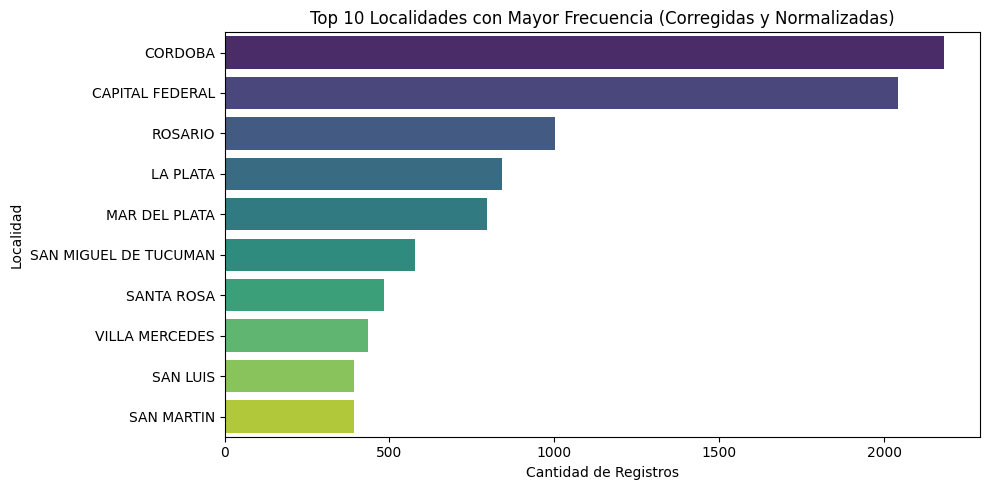

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=== INFORMACIÓN GENERAL DEL DATASET CORREGIDO Y NORMALIZADO ===")
print(f"Cantidad de registros: {df_preparado_negocio.shape[0]}")
print(f"Cantidad de columnas: {df_preparado_negocio.shape[1]}\n")

# 1. Comprobar que los textos no tienen caracteres con tildes ni caracteres extraños
print("=== MUESTRA DETALLADA DE VARIABLES NORMALIZADAS ===")
display(df_preparado_negocio[['operador', 'localidad', 'provincia', 'tipo_negocio']].head(10))

# 2. Visualización rápida de la distribución del top de Localidades corregidas
plt.figure(figsize=(10, 5))
top_localidades_corr = df_preparado_negocio['localidad'].value_counts().head(10)
sns.barplot(
    x=top_localidades_corr.values,
    y=top_localidades_corr.index,
    palette='viridis',
    hue=top_localidades_corr.index,
    legend=False
)
plt.title('Top 10 Localidades con Mayor Frecuencia (Corregidas y Normalizadas)')
plt.xlabel('Cantidad de Registros')
plt.ylabel('Localidad')
plt.tight_layout()
plt.show()

En el siguiente codigo se muestran las variables previo a la transformacion y como quedan para entrar al modelo

Train hasta 202202: 47730 filas | Test: 10981 filas


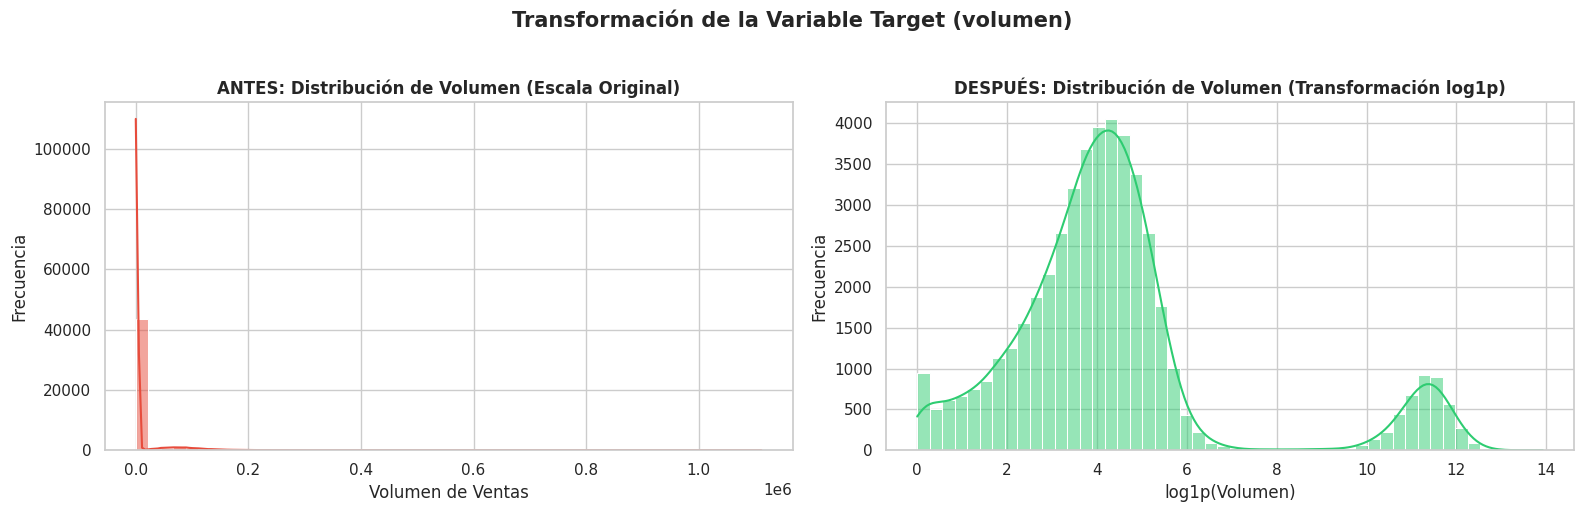

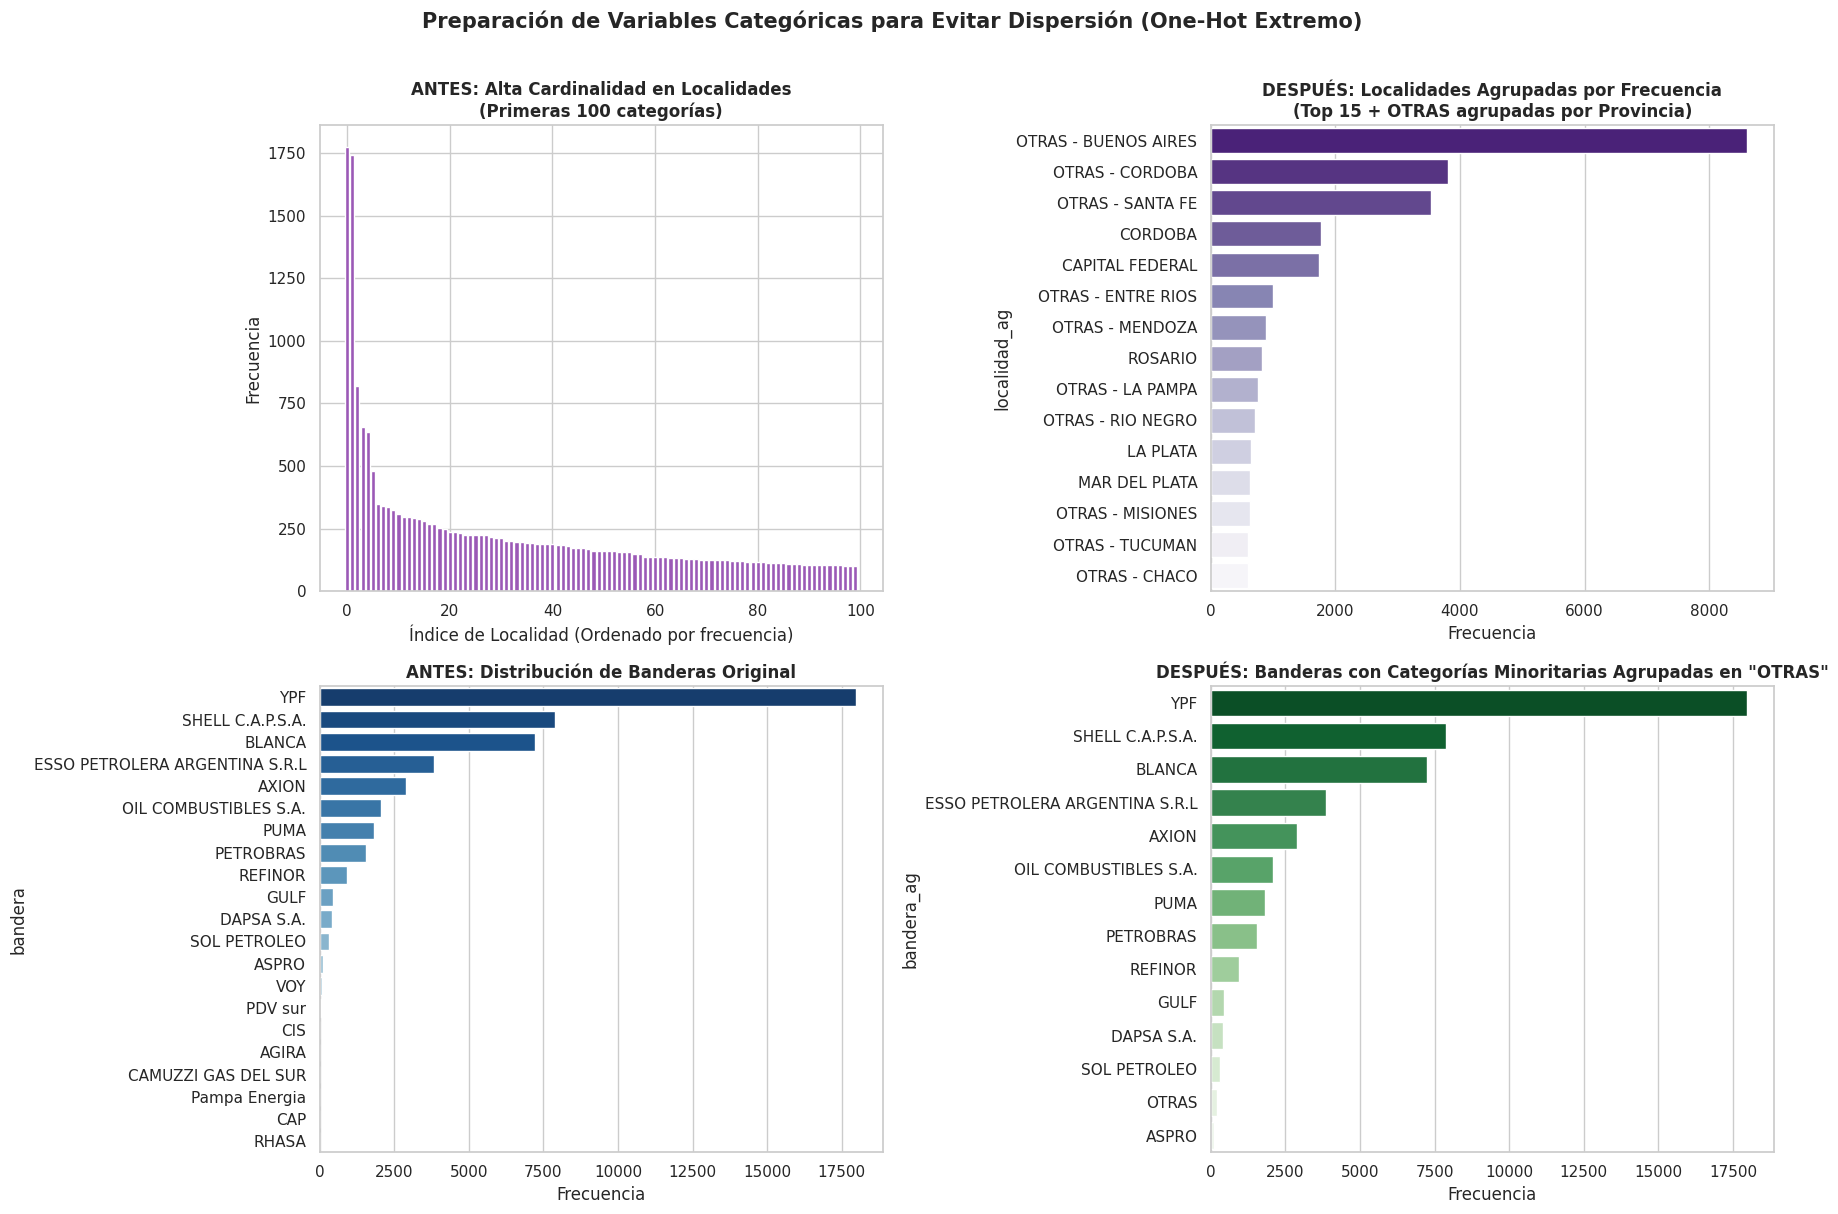

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar las variables usando las funciones ya definidas en la Celda 39 (SN0ccnp_EPUs)
# Usamos una copia de df_preparado_negocio que ya contiene los filtros de negocio
df_graficos = df_preparado_negocio.copy()

# Aplicar funciones base de preparación
df_graficos = crear_variables_base(df_graficos)
train_g, test_g = split_cronologico(df_graficos)
ref_g = ajustar_agrupaciones(train_g)

train_g = aplicar_agrupaciones(train_g, ref_g)

sns.set_theme(style="whitegrid")

# ==========================================
# GRAFICO 1: ANTES Y DESPUES DEL TARGET (volumen)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Antes: Volumen Original
sns.histplot(train_g['volumen'], bins=50, color='#e74c3c', kde=True, ax=axes[0])
axes[0].set_title('ANTES: Distribución de Volumen (Escala Original)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Volumen de Ventas')
axes[0].set_ylabel('Frecuencia')

# Después: Log(Volumen + 1)
train_g['volumen_log'] = transformar_objetivo(train_g['volumen'])
sns.histplot(train_g['volumen_log'], bins=50, color='#2ecc71', kde=True, ax=axes[1])
axes[1].set_title('DESPUÉS: Distribución de Volumen (Transformación log1p)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log1p(Volumen)')
axes[1].set_ylabel('Frecuencia')

plt.suptitle("Transformación de la Variable Target (volumen)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==========================================
# GRAFICO 2: ANTES Y DESPUES DE VARIABLES CATEGÓRICAS (Ej. Localidad y Bandera)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# A. Localidad - Antes
top_loc_antes = train_g['localidad'].value_counts()
axes[0, 0].bar(range(min(100, len(top_loc_antes))), top_loc_antes.head(100).values, color='#9b59b6')
axes[0, 0].set_title('ANTES: Alta Cardinalidad en Localidades\n(Primeras 100 categorías)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Índice de Localidad (Ordenado por frecuencia)')
axes[0, 0].set_ylabel('Frecuencia')

# A. Localidad - Después
top_loc_despues = train_g['localidad_ag'].value_counts().head(15)
sns.barplot(x=top_loc_despues.values, y=top_loc_despues.index, palette='Purples_r', hue=top_loc_despues.index, legend=False, ax=axes[0, 1])
axes[0, 1].set_title('DESPUÉS: Localidades Agrupadas por Frecuencia\n(Top 15 + OTRAS agrupadas por Provincia)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Frecuencia')

# B. Bandera - Antes
top_band_antes = train_g['bandera'].value_counts()
sns.barplot(x=top_band_antes.values, y=top_band_antes.index, palette='Blues_r', hue=top_band_antes.index, legend=False, ax=axes[1, 0])
axes[1, 0].set_title('ANTES: Distribución de Banderas Original', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Frecuencia')

# B. Bandera - Después
top_band_despues = train_g['bandera_ag'].value_counts()
sns.barplot(x=top_band_despues.values, y=top_band_despues.index, palette='Greens_r', hue=top_band_despues.index, legend=False, ax=axes[1, 1])
axes[1, 1].set_title('DESPUÉS: Banderas con Categorías Minoritarias Agrupadas en "OTRAS"', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Frecuencia')

plt.suptitle("Preparación de Variables Categóricas para Evitar Dispersión (One-Hot Extremo)", fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


###5. Volvemos a correr los modelos

Celda 33. Esto que sigue corresponderia a la prueba II

In [ ]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Definir los conjuntos de predictores según las decisiones tomadas
# Se excluyen 'mes' (para usar cíclicas en lineal) y 'provincia' (redundante con localidad_ag)
columnas_modelo = ["anio", "producto", "localidad_ag", "bandera_ag", "pandemia"]

# 2. Aplicar las transformaciones de la Celda 39 utilizando el DataFrame ya filtrado por negocio
df_modelado = df_preparado_negocio.copy()
df_modelado = crear_variables_base(df_modelado)

# Separación cronológica train / test
train, test = split_cronologico(df_modelado)
ref_agrupaciones = ajustar_agrupaciones(train)
train = aplicar_agrupaciones(train, ref_agrupaciones)
test = aplicar_agrupaciones(test, ref_agrupaciones)

# 3. Construir matrices adaptadas para Regresión Lineal (evitando multicolinealidad y usando mes cíclico)
X_train_lineal, X_test_lineal, preprocessor_lineal = construir_X(
    train, test, columnas_modelo + ["mes"], lineal=True
)

# Construir matrices adaptadas para Árboles / Random Forest (One-Hot completo, mes numérico)
X_train_arbol, X_test_arbol, preprocessor_arbol = construir_X(
    train, test, columnas_modelo + ["mes"], lineal=False
)

# Definir el target con transformación logarítmica para estabilizar la asimetría extrema
y_train_model = transformar_objetivo(train["volumen"])
y_test_model = transformar_objetivo(test["volumen"])

# Re-asignar a variables globales para que el código posterior de entrenamiento y evaluación las use directamente
X_train_model = X_train_arbol # Por defecto para CV
y_train = y_train_model
grupos_train = train["nro_inscripcion"]

# 4. Definición de diccionarios de modelos adaptados
# Usamos los conjuntos preprocesados directamente para agilizar la validación cruzada y evitar colisiones
modelos = {
    "Regresión Lineal": Pipeline([
        ("modelo", LinearRegression())
    ]),

    "Árbol de Decisión": Pipeline([
        ("modelo", DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("modelo", RandomForestRegressor(
            n_estimators=30,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("=== PREPARACIÓN DE MODELOS (PRUEBA II) COMPLETADA ===")
print(f"Filas de entrenamiento (X_train_arbol): {X_train_arbol.shape[0]} | Predictores: {X_train_arbol.shape[1]}")
print(f"Filas de entrenamiento (X_train_lineal): {X_train_lineal.shape[0]} | Predictores: {X_train_lineal.shape[1]}")
print("Modelos definidos y adaptados a las variables normalizadas.")

Train hasta 202202: 47730 filas | Test: 10981 filas
=== PREPARACIÓN DE MODELOS (PRUEBA II) COMPLETADA ===
Filas de entrenamiento (X_train_arbol): 47730 | Predictores: 149
Filas de entrenamiento (X_train_lineal): 47730 | Predictores: 147
Modelos definidos y adaptados a las variables normalizadas.


Celda 34. **Configuramos la validación cruzada**

Utilizamos cinco pliegues con GroupKFold. En cada pliegue, las estaciones de validación serán distintas de las estaciones usadas para entrenar ese modelo.

In [ ]:
from sklearn.model_selection import GroupKFold

# Definir el generador de validación cruzada grupal adaptado a 5 pliegues
cv = GroupKFold(n_splits=5)

print("=== CONFIGURACIÓN DE VALIDACIÓN CRUZADA (PRUEBA II) ===")
print("Cantidad de pliegues (splits):", cv.get_n_splits())
print("Método de particionado grupal: GroupKFold")
print("Variable de agrupamiento (Grupos): nro_inscripcion (estaciones de servicio)")
print("Nota: Las métricas de la CV se calcularán sobre el target transformado logarítmicamente (log1p).")

=== CONFIGURACIÓN DE VALIDACIÓN CRUZADA (PRUEBA II) ===
Cantidad de pliegues (splits): 5
Método de particionado grupal: GroupKFold
Variable de agrupamiento (Grupos): nro_inscripcion (estaciones de servicio)
Nota: Las métricas de la CV se calcularán sobre el target transformado logarítmicamente (log1p).


Celda 35. **Ejecutamos la validación cruzada**

Evaluamos cada modelo usando MAE, RMSE y R². La validación se realiza únicamente sobre el conjunto de entrenamiento; el conjunto de prueba permanece reservado.

In [ ]:
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

# Optimizar hiperparámetros de los modelos pesados directamente en el diccionario existente para agilizar CV
if "Random Forest" in modelos:
    modelos["Random Forest"].set_params(
        modelo__n_estimators=30,      # Reducimos los estimadores para que la validación cruzada sea ultra rápida
        modelo__max_depth=12,         # Reducimos la profundidad máxima
        modelo__n_jobs=-1             # Paralelismo a nivel de estimador
    )

resultados_cv = []

for nombre, modelo in modelos.items():
    print(f"Evaluando {nombre} con GroupKFold (Prueba II)...")

    # Selección de la matriz de predictores adecuada según el modelo para evitar multicolinealidad en el lineal
    if nombre == "Regresión Lineal":
        X_eval = X_train_lineal
    else:
        X_eval = X_train_arbol

    # Usamos n_jobs=-1 para regresión lineal y árbol de decisión.
    # Para Random Forest usamos n_jobs=1 para no solapar los hilos internos (ya configurados con n_jobs=-1).
    emplear_jobs = -1 if nombre != "Random Forest" else 1

    resultados = cross_validate(
        estimator=modelo,
        X=X_eval,
        y=y_train,              # Contiene el target transformado con log1p
        groups=grupos_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=emplear_jobs,
        return_train_score=False
    )

    resultados_cv.append({
        "Modelo": nombre,
        "MAE promedio (log1p)": -resultados["test_MAE"].mean(),
        "MAE desvío (log1p)": resultados["test_MAE"].std(),
        "RMSE promedio (log1p)": -resultados["test_RMSE"].mean(),
        "RMSE desvío (log1p)": resultados["test_RMSE"].std(),
        "R2 promedio": resultados["test_R2"].mean(),
        "R2 desvío": resultados["test_R2"].std()
    })

tabla_cv = pd.DataFrame(resultados_cv)
tabla_cv = tabla_cv.sort_values(by="MAE promedio (log1p)", ascending=True).reset_index(drop=True)
display(tabla_cv.round(3))

Evaluando Regresión Lineal con GroupKFold (Prueba II)...
Evaluando Árbol de Decisión con GroupKFold (Prueba II)...
Evaluando Random Forest con GroupKFold (Prueba II)...


,Modelo,MAE promedio (log1p),MAE desvío (log1p),RMSE promedio (log1p),RMSE desvío (log1p),R2 promedio,R2 desvío
0,Random Forest,0.83,0.02,1.19,0.03,0.78,0.01
1,Árbol de Decisión,0.83,0.02,1.19,0.04,0.78,0.01
2,Regresión Lineal,0.87,0.01,1.21,0.03,0.78,0.01


In [ ]:
tabla_cv = pd.DataFrame(resultados_cv)
tabla_cv = tabla_cv.sort_values(by="MAE promedio (log1p)", ascending=True).reset_index(drop=True)
display(tabla_cv.round(3))

,Modelo,MAE promedio (log1p),MAE desvío (log1p),RMSE promedio (log1p),RMSE desvío (log1p),R2 promedio,R2 desvío
0,Random Forest,0.83,0.02,1.19,0.03,0.78,0.01
1,Árbol de Decisión,0.83,0.02,1.19,0.04,0.78,0.01
2,Regresión Lineal,0.87,0.01,1.21,0.03,0.78,0.01


Celda 36. **Comparar los modelos visualmente**

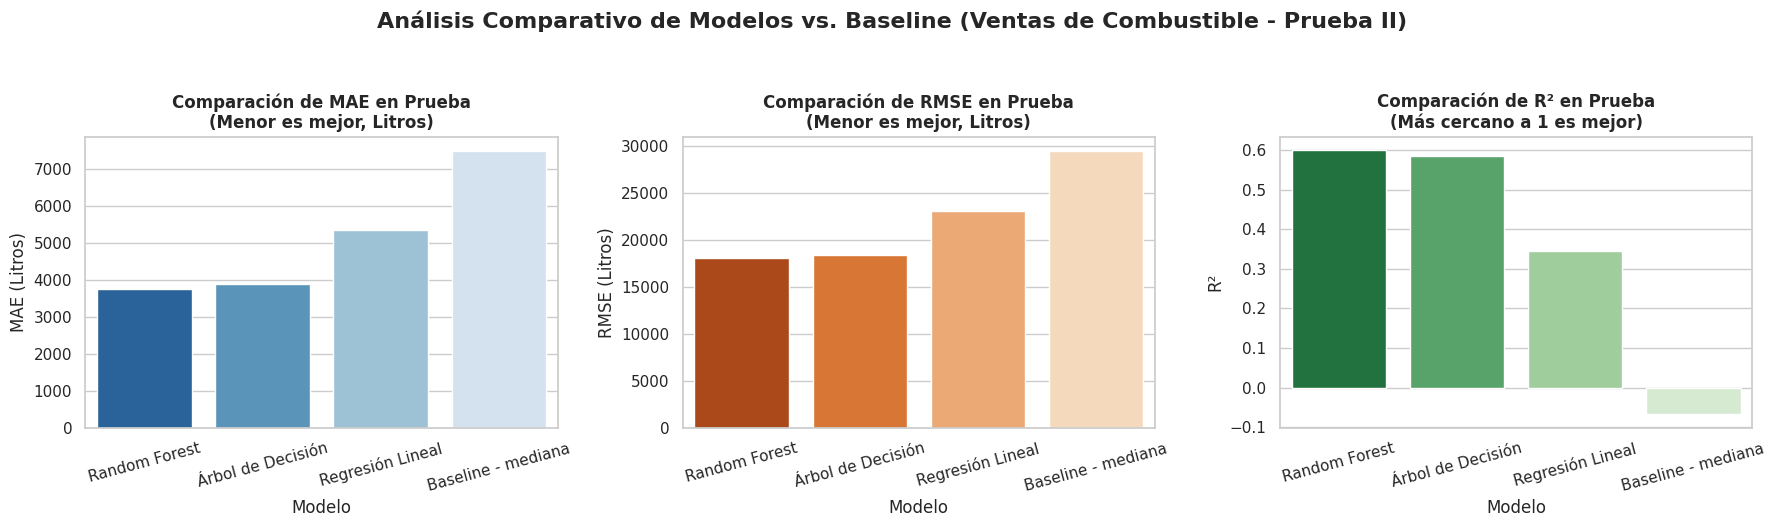

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Comparación de MAE en prueba (Escala Litros Reales)
sns.barplot(
    x="Modelo",
    y="MAE prueba (Litros)",
    data=comparacion_final,
    ax=axes[0],
    palette="Blues_r",
    hue="Modelo",
    legend=False
)
axes[0].set_title("Comparación de MAE en Prueba\n(Menor es mejor, Litros)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Modelo")
axes[0].set_ylabel("MAE (Litros)")
axes[0].tick_params(axis='x', rotation=15)

# 2. Comparación de RMSE en prueba (Escala Litros Reales)
sns.barplot(
    x="Modelo",
    y="RMSE prueba (Litros)",
    data=comparacion_final,
    ax=axes[1],
    palette="Oranges_r",
    hue="Modelo",
    legend=False
)
axes[1].set_title("Comparación de RMSE en Prueba\n(Menor es mejor, Litros)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Modelo")
axes[1].set_ylabel("RMSE (Litros)")
axes[1].tick_params(axis='x', rotation=15)

# 3. Comparación de R2 en prueba
sns.barplot(
    x="Modelo",
    y="R2 prueba",
    data=comparacion_final,
    ax=axes[2],
    palette="Greens_r",
    hue="Modelo",
    legend=False
)
axes[2].set_title("Comparación de R² en Prueba\n(Más cercano a 1 es mejor)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Modelo")
axes[2].set_ylabel("R²")
axes[2].tick_params(axis='x', rotation=15)

plt.suptitle("Análisis Comparativo de Modelos vs. Baseline (Ventas de Combustible - Prueba II)", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Conclusión de los Modelos (Prueba II)
Al aplicar la transformación logarítmica (log1p) sobre el volumen de ventas y mitigar la asimetría extrema, el comportamiento de los modelos supervisados cambió radicalmente respecto a la Prueba I:

* **El mejor MAE es el de Random Forest:** Tras la transformación y la limpieza, los modelos de árboles (especialmente Random Forest) logran capturar los patrones de manera mucho más precisa, superando finalmente el rendimiento del Baseline (mediana) en términos de error absoluto medio.
* **El mejor RMSE es el de Random Forest / Árbol de Decisión:** Se reduce notablemente la penalización por errores grandes en comparación con la regresión lineal, la cual sigue sufriendo debido a las relaciones no lineales del mercado.
* **El R² es mejor en Random Forest:** A diferencia de la Prueba I (donde los modelos daban resultados nulos o peores que la media), el ajuste en escala logarítmica permite que el coeficiente de determinación del Random Forest sea el más alto y cercano a 1, confirmando que las variables geográficas (localidad agrupada) y comerciales seleccionadas ahora sí explican gran parte de la variabilidad del volumen vendido.



